In [160]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nglview as nv

from ase import Atoms
from ase.io import read, write
from ase.geometry import find_mic

from zse.cif_tools import read_cif, cif_site_labels
from zse.rings import get_rings, get_unique_rings
from itertools import combinations, product
import contextlib
import io
import spglib
from math import ceil
from ase.data import covalent_radii, atomic_numbers
from scipy.spatial import cKDTree
from ase import Atom
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

DATA_DIR = Path("data")
cif_files = {p.stem: p for p in sorted((DATA_DIR / "zeolite_cifs").glob("*.cif"))}

In [104]:
print(f"Available frameworks: {len(cif_files)}")
print(sorted(cif_files))

Available frameworks: 42
['AEI', 'AEL', 'AFI', 'AFX', 'ATO', 'Beta_A', 'CHA', 'CON', 'DDR', 'EAB', 'EMT', 'ERI', 'EUO', 'FAU', 'FER', 'GIS', 'GME', 'HEU', 'IFR', 'ITH', 'IWW', 'KFI', 'LEV', 'LTA', 'LTL', 'MAZ', 'MEL', 'MFI', 'MFS', 'MOR', 'MTW', 'MWW', 'OFF', 'PAU', 'PHI', 'RHO', 'RUT', 'SAV', 'SOD', 'STT', 'TON', 'UTL']


In [ ]:
def load_framework(code):
    path = cif_files[code]
    atoms, ts, tm, tinds, os, om, oinds = read_cif(str(path))
    labels = cif_site_labels(str(path))

    atoms.pbc = True

    metadata = {
        "code": code,
        "t_sites": ts,
        "t_multiplicities": tm,
        "t_indices": tinds,
        "o_sites": os,
        "o_multiplicities": om,
        "o_indices": oinds,
        "site_labels": labels,
    }

    return atoms, metadata


def show_structure(atoms, repeat=(1, 1, 1), highlight_indices=None, labels=None):
    viewer = nv.show_ase(atoms.repeat(repeat))
    viewer.clear_representations()

    viewer.add_ball_and_stick(aspectRatio=1.5)

    if highlight_indices is not None:
        indices = [int(i) for i in highlight_indices]
        n = len(atoms)
        selected = [i + k*n for k in range(int(np.prod(repeat))) for i in indices]
        selection = "@" + ",".join(map(str, selected))

        viewer.add_ball_and_stick(selection=selection, color="blue", aspectRatio=1.5)

        if labels is not None:
            if len(labels) != len(indices):
                raise ValueError("labels must have the same length as highlight_indices")

            for i, label in zip(indices, labels):
                atom_selection = "@" + ",".join(
                    str(i + k*n) for k in range(int(np.prod(repeat)))
                )
                viewer.add_label(
                    selection=atom_selection,
                    labelType="text",
                    labelText=str(label),
                    color="black",
                    zOffset=1.5
                )

    viewer.center()
    return viewer


def get_t_o_neighbors(atoms, cutoff=2.1):
    t_indices = np.array([a.index for a in atoms if a.symbol in ("Si", "Al")])
    o_indices = np.array([a.index for a in atoms if a.symbol == "O"])

    neighbors = {}

    for i in t_indices:
        distances = atoms.get_distances(i, o_indices, mic=True)
        neighbors[int(i)] = o_indices[distances < cutoff].tolist()

    return neighbors

def find_rings(atoms, index, max_ring=12):
    """just a non-noise wrapper around get_rings"""
    with contextlib.redirect_stdout(io.StringIO()):
        return get_rings(atoms, index=index, max_ring=max_ring, validation="goetzke")

def map_ring_path(atoms, repeated_atoms, path, tol=0.15):
    path = np.asarray(path, dtype=int)
    n = len(atoms)

    if np.any(path < 0) or np.any(path >= len(repeated_atoms)):
        raise ValueError("Invalid ring path indices")

    indices = path % n

    # Verify that the repeated structure preserves atom ordering
    for original, repeated in zip(indices, path):
        if atoms[original].symbol != repeated_atoms[repeated].symbol:
            raise ValueError("Repeated atom ordering does not match original")

        delta = repeated_atoms.positions[repeated] - atoms.positions[original]
        _, distance = find_mic(delta, atoms.cell, atoms.pbc)

        if distance > tol:
            raise ValueError("Repeated coordinates do not match original")

    # Reconstruct a continuous ring using consecutive bond vectors
    positions = repeated_atoms.positions[path]
    vectors, distances = find_mic(
        np.diff(positions, axis=0), atoms.cell, atoms.pbc
    )

    if np.any(distances > 2.1):
        raise ValueError("Ring contains unexpectedly long bonds")

    unwrapped = np.vstack([
        positions[0],
        positions[0] + np.cumsum(vectors, axis=0)
    ])

    t_mask = np.array([
        atoms[i].symbol in ("Si", "Al") for i in indices
    ])

    return indices[t_mask].tolist(), unwrapped[t_mask]

def substitute_al(atoms, al_indices):
    structure = atoms.copy()
    for i in al_indices:
        if structure[i].symbol != "Si":
            raise ValueError(f"Atom {i} is not Si")
        structure[i].symbol = "Al"
    return structure



def valid_al_pairs(atoms, t_indices, max_distance=9.0):
    neighbors = {i: set(v) for i, v in get_t_o_neighbors(atoms).items()}
    pairs = []

    for i, j in combinations(sorted(set(map(int, t_indices))), 2):
        if atoms[i].symbol != "Si" or atoms[j].symbol != "Si":
            continue

        # Löwenstein's rule: Al atoms cannot share an oxygen
        if neighbors[i] & neighbors[j]:
            continue

        distance = atoms.get_distance(i, j, mic=True)
        if distance <= max_distance:
            pairs.append((i, j))

    return pairs



def distances_to_framework(atoms, position):
    delta, _ = find_mic(atoms.positions - position, atoms.cell, atoms.pbc)
    return np.linalg.norm(delta, axis=1)


def coordination_info(atoms, position, cutoff=3.0):
    distances = distances_to_framework(atoms, position)
    o_indices = np.array([a.index for a in atoms if a.symbol == "O"])
    t_indices = np.array([a.index for a in atoms if a.symbol in ("Si", "Al")])

    return {
        "n_o": int(np.sum(distances[o_indices] < cutoff)),
        "min_o": float(distances[o_indices].min()),
        "min_t": float(distances[t_indices].min()),
        "o_indices": o_indices[distances[o_indices] < cutoff].tolist()
    }


def unique_positions(atoms, positions, min_separation=0.5):
    selected = []
    for pos in positions:
        if not any(
            np.linalg.norm(find_mic(pos - other, atoms.cell, atoms.pbc)[0]) < min_separation
            for other in selected
        ):
            selected.append(np.asarray(pos))
    return selected


def ring_geometry(coords):
    centre = np.asarray(coords).mean(axis=0)
    _, _, vh = np.linalg.svd(np.asarray(coords) - centre)
    normal = vh[-1]
    return centre, normal / np.linalg.norm(normal)


def get_framework_symmetry(atoms, symprec=0.01):
    cell = (
        np.asarray(atoms.cell),
        atoms.get_scaled_positions(wrap=True),
        atoms.get_atomic_numbers()
    )

    symmetry = spglib.get_symmetry(cell, symprec=symprec)

    if symmetry is None:
        raise ValueError("Could not identify framework symmetry")

    print(f"Symmetry operations: {len(symmetry['rotations'])}")
    return symmetry

def get_t_permutations(atoms, symmetry, tol=0.05):
    t_indices = np.array([a.index for a in atoms if a.symbol in ("Si", "Al")])
    scaled = atoms.get_scaled_positions(wrap=True)
    t_scaled = scaled[t_indices]

    permutations = []
    positions = atoms.positions[t_indices]

    for rotation, translation in zip(symmetry["rotations"], symmetry["translations"]):
        transformed = (t_scaled @ rotation.T + translation) @ np.asarray(atoms.cell)

        mapping = {}
        for idx, pos in zip(t_indices, transformed):
            delta, distances = find_mic(positions - pos, atoms.cell, atoms.pbc)
            j = np.argmin(distances)

            if distances[j] > tol:
                raise ValueError(f"Symmetry mapping failed: {distances[j]:.3f} Å")

            mapping[int(idx)] = int(t_indices[j])

        if len(set(mapping.values())) != len(t_indices):
            raise ValueError("Symmetry operation did not produce a valid permutation")

        permutations.append(mapping)

    return permutations


def unique_al_pairs(pairs, permutations):
    pairs = {tuple(sorted(map(int, pair))) for pair in pairs}
    remaining = pairs.copy()
    unique = []

    while remaining:
        pair = min(remaining)

        equivalents = {
            tuple(sorted((perm[pair[0]], perm[pair[1]])))
            for perm in permutations
        }

        matches = equivalents & pairs

        unique.append({
            "al_pair": pair,
            "multiplicity": len(matches),
            "equivalent_pairs": sorted(matches)
        })

        remaining.difference_update(matches)

    return unique

def pair_center(atoms, i, j):
    """Periodic midpoint between two atoms."""
    vector = atoms.get_distance(i, j, mic=True, vector=True)
    return atoms.positions[i] + 0.5 * vector




import numpy as np
import matplotlib.pyplot as plt
from math import ceil
from ase.geometry import find_mic

def pair_center(atoms, i, j):
    vector = atoms.get_distance(i, j, mic=True, vector=True)
    return atoms.positions[i] + 0.5 * vector

def unwrap_ring_positions(atoms, ring_indices, view_centre=None):
    """
    Return continuous Cartesian coordinates for a ring defined by ordered atom indices.
    ring_indices should be in cyclic order around the ring.
    """
    ring_indices = [int(i) for i in ring_indices]
    pos = atoms.positions

    coords = [pos[ring_indices[0]].copy()]

    for prev, curr in zip(ring_indices[:-1], ring_indices[1:]):
        vec = atoms.get_distance(prev, curr, mic=True, vector=True)
        coords.append(coords[-1] + vec)

    coords = np.asarray(coords)

    # If a view centre is supplied, shift the whole ring so it sits near that centre
    if view_centre is not None:
        ring_centre = coords.mean(axis=0)
        shift_vec = view_centre - ring_centre
        shift_mic, _ = find_mic(shift_vec, atoms.cell, atoms.pbc)
        coords = coords + shift_mic

    return coords


def get_zse_rings(atoms, t_indices, sizes=(4, 6)):
    rings = {}
    n = len(atoms)
    symbols = np.array(atoms.get_chemical_symbols())

    for t in sorted(set(map(int, t_indices))):
        with contextlib.redirect_stdout(io.StringIO()):
            ring_sizes, ring_paths, _, repeated = get_rings(
                atoms, index=t, max_ring=max(sizes), validation="goetzke"
            )

        repeated_symbols = np.array(repeated.get_chemical_symbols())

        for size, path in zip(ring_sizes, ring_paths):
            size = int(size)
            if size not in sizes:
                continue

            path = np.asarray(path, dtype=int)
            ids = path % n
            ring_symbols = repeated_symbols[path]

            if len(path) != 2 * size:
                continue

            # Validate original-atom mapping and alternating T–O sequence
            if not np.array_equal(ring_symbols, symbols[ids]):
                continue

            is_t = np.isin(ring_symbols, ["Si", "Al"])
            if is_t.sum() != size or np.any(is_t == np.roll(is_t, 1)):
                continue

            # Reconstruct along the actual T–O–T ring path
            coords = [repeated.positions[path[0]].copy()]

            for a, b in zip(path[:-1], path[1:]):
                vector, distance = find_mic(
                    repeated.positions[b] - repeated.positions[a],
                    atoms.cell, atoms.pbc
                )
                if distance > 2.2:
                    break
                coords.append(coords[-1] + vector)

            if len(coords) != len(path):
                continue

            coords = np.asarray(coords)

            # Check final O–T closure, including periodic continuity
            closing, distance = find_mic(
                repeated.positions[path[0]] - repeated.positions[path[-1]],
                atoms.cell, atoms.pbc
            )
            if distance > 2.2 or np.linalg.norm(coords[-1] + closing - coords[0]) > 0.3:
                continue

            t_ids = ids[is_t].tolist()
            t_coords = coords[is_t]

            # Reject duplicate / unrealistically extended polygons
            edges = np.linalg.norm(np.roll(t_coords, -1, axis=0) - t_coords, axis=1)
            if edges.max() > 4.0:
                continue

            key = (size, tuple(sorted(t_ids)))
            if key not in rings:
                rings[key] = {
                    "size": size,
                    "t_indices": t_ids,
                    "coords": t_coords
                }

    return list(rings.values())



def plot_structure_grid(structures, centers=None, center_indices=None,
                        highlight_indices=None, titles=None, radius=6.0,
                        ncols=3, figsize=None, elev=25, azim=45,
                        show_labels=False, repeat=(3, 3, 3),
                        cation_indices=None, coord_cutoff=2.7,
                        ring_overlays=False):

    n = len(structures)
    nrows = ceil(n / ncols)
    figsize = figsize or (4.5 * ncols, 4.2 * nrows)
    fig = plt.figure(figsize=figsize)

    colors = {
        "Si": "#D4B04C", "Al": "#2276C7", "O": "#D95743",
        "Cu": "#B87333", "Ca": "#559B83",
        "Zn": "#7B8794", "Mn": "#9567A5", "H": "#E5E5E5"
    }
    sizes = {"O": 25, "H": 12, "Si": 48, "Al": 48}
    ring_colors = {4: "#22A06B", 6: "#E5A12B"}

    # Find relevant rings once using the framework without cations
    zse_rings = []
    if ring_overlays:
        base = structures[0].copy()
        nonframework = [a.index for a in base if a.symbol not in ("Si", "Al", "O")]
        if nonframework:
            del base[nonframework]

        # Use the ideal all-silica topology to identify rings consistently
        for atom in base:
            if atom.symbol == "Al":
                atom.symbol = "Si"

        if highlight_indices is not None:
            t_indices = sorted({
                int(i)
                for k, atoms in enumerate(structures)
                for i in highlight_indices[k]
                if atoms[int(i)].symbol in ("Si", "Al")
            })
        else:
            t_indices = [a.index for a in base if a.symbol == "Si"]

        zse_rings = get_zse_rings(base, t_indices)
        print(f"ZSE identified {sum(r['size'] == 4 for r in zse_rings)} 4MRs "
              f"and {sum(r['size'] == 6 for r in zse_rings)} 6MRs")

    for k, atoms in enumerate(structures):
        ax = fig.add_subplot(nrows, ncols, k + 1, projection="3d")

        if centers is not None:
            centre = np.asarray(centers[k], dtype=float)
        elif center_indices is not None:
            centre = atoms.positions[int(center_indices[k])]
        else:
            centre = atoms.positions.mean(axis=0)

        # Generate periodic images
        cell = np.asarray(atoms.cell)
        translations = [
            a*cell[0] + b*cell[1] + c*cell[2]
            for a in range(-(repeat[0]//2), repeat[0]//2 + 1)
            for b in range(-(repeat[1]//2), repeat[1]//2 + 1)
            for c in range(-(repeat[2]//2), repeat[2]//2 + 1)
        ]

        xyz, symbols, original_indices = [], [], []
        atom_symbols = np.asarray(atoms.get_chemical_symbols())

        for translation in translations:
            shifted = atoms.positions + translation - centre
            inside = np.linalg.norm(shifted, axis=1) <= radius

            xyz.extend(shifted[inside])
            symbols.extend(atom_symbols[inside])
            original_indices.extend(np.where(inside)[0])

        xyz = np.asarray(xyz).reshape(-1, 3)
        symbols = np.asarray(symbols)
        original_indices = np.asarray(original_indices, dtype=int)

        if len(xyz) == 0:
            continue

        selected = (
            set(map(int, highlight_indices[k]))
            if highlight_indices is not None else set()
        )

        # -------------------------------------------------------
        # Automatically shade 4MR and 6MR rings
        # -------------------------------------------------------
        if ring_overlays:
            visible_rings = []

            for ring in zse_rings:
                coords = ring["coords"].copy()

                # Shift the entire ring to its nearest periodic image
                ring_centre = coords.mean(axis=0)
                delta = centre - ring_centre
                mic_vector, _ = find_mic(delta, atoms.cell, atoms.pbc)

                coords += delta - mic_vector
                coords -= centre

                distance = np.linalg.norm(coords.mean(axis=0))
                if distance > radius:
                    continue

                n_selected = len(set(ring["t_indices"]) & selected)
                visible_rings.append((n_selected, distance, ring["size"], coords))

            # Prioritise nearby rings and rings containing highlighted Al
            visible_rings.sort(key=lambda x: (-x[0], x[1]))
            visible_rings = visible_rings[:16]

            for n_selected, distance, size, coords in visible_rings:
                color = ring_colors[size]
                alpha = 0.22 if n_selected >= 2 else 0.07

                # Triangulate to accommodate nonplanar rings
                rc = coords.mean(axis=0)
                triangles = [
                    [rc, coords[i], coords[(i + 1) % len(coords)]]
                    for i in range(len(coords))
                ]

                ax.add_collection3d(Poly3DCollection(
                    triangles,
                    facecolors=color,
                    edgecolors="none",
                    alpha=alpha,
                    zsort="average"
                ))

                closed = np.vstack([coords, coords[0]])
                ax.plot(
                    closed[:, 0], closed[:, 1], closed[:, 2],
                    color=color,
                    linewidth=1.4 if n_selected >= 2 else 0.7,
                    alpha=0.75 if n_selected >= 2 else 0.25
                )

        # -------------------------------------------------------
        # Framework T–O bonds
        # -------------------------------------------------------
        t_indices = np.where(np.isin(symbols, ["Si", "Al"]))[0]
        o_indices = np.where(symbols == "O")[0]

        for i in t_indices:
            for j in o_indices:
                if np.linalg.norm(xyz[i] - xyz[j]) < 2.1:
                    ax.plot(
                        *zip(xyz[i], xyz[j]),
                        color="#89939D",
                        lw=1.1,
                        alpha=0.6
                    )

        # -------------------------------------------------------
        # Dashed cation–oxygen coordination bonds
        # -------------------------------------------------------
        if cation_indices is not None:
            metal_index = int(cation_indices[k])
            metal_images = np.where(original_indices == metal_index)[0]

            if len(metal_images):
                m = metal_images[
                    np.argmin(np.linalg.norm(xyz[metal_images], axis=1))
                ]
                metal_pos = xyz[m]
                nearest_o = {}

                for oi in o_indices:
                    original = int(original_indices[oi])
                    distance = np.linalg.norm(xyz[oi] - metal_pos)

                    if distance < coord_cutoff:
                        if original not in nearest_o or distance < nearest_o[original][0]:
                            nearest_o[original] = (distance, oi)

                for distance, oi in nearest_o.values():
                    ax.plot(
                        [metal_pos[0], xyz[oi, 0]],
                        [metal_pos[1], xyz[oi, 1]],
                        [metal_pos[2], xyz[oi, 2]],
                        linestyle="--",
                        color="#B87333",
                        linewidth=1.8,
                        alpha=0.9
                    )

        # -------------------------------------------------------
        # Draw atoms
        # -------------------------------------------------------
        for pos, symbol, original in zip(xyz, symbols, original_indices):
            color = "#16A6E0" if original in selected else colors.get(symbol, "#888888")

            ax.scatter(
                *pos,
                color=color,
                s=sizes.get(symbol, 65),
                edgecolors="white",
                linewidths=0.3,
                depthshade=True
            )

            if show_labels and original in selected:
                ax.text(*(pos + 0.2), str(original), fontsize=8)

        ax.set_xlim(-radius, radius)
        ax.set_ylim(-radius, radius)
        ax.set_zlim(-radius, radius)
        ax.set_box_aspect((1, 1, 1))
        ax.view_init(elev=elev, azim=azim)
        ax.set_axis_off()

        if titles is not None:
            ax.set_title(titles[k], fontsize=11, pad=0)

    plt.tight_layout()
    return fig




def describe_al_pairs(framework, unique_pairs, rings):
    neighbors = get_t_o_neighbors(framework)
    rows = []

    for entry in unique_pairs:
        i, j = entry["al_pair"]
        o1, o2 = list(neighbors[i]), list(neighbors[j])

        d_oo = framework.get_distances(o1[0], o2, mic=True) if False else None
        oxygen_distances = np.array([
            framework.get_distance(a, b, mic=True)
            for a in o1 for b in o2
        ])

        shared_ring = any(
            i in ring["t_indices"] and j in ring["t_indices"]
            for ring in rings
        )

        rows.append({
            "al1": i,
            "al2": j,
            "al_al_A": framework.get_distance(i, j, mic=True),
            "min_o_o_A": oxygen_distances.min(),
            "same_6mr": shared_ring,
            "multiplicity": entry["multiplicity"]
        })

    return pd.DataFrame(rows)

def find_m2_pockets(atoms, al_pair, metal="Cu", search_radius=3.0,
                    spacing=0.4, target_mo=2.05, max_mo=2.7,
                    min_mo=1.7, min_mt=2.4, n_sites=5):
    """Find positions with at least 2 nearby framework O from each Al."""
    i, j = map(int, al_pair)
    neighbors = get_t_o_neighbors(atoms)
    o1, o2 = set(neighbors[i]), set(neighbors[j])

    if o1 & o2:
        return []

    centre = atoms.positions[i] + 0.5 * atoms.get_distance(i, j, mic=True, vector=True)
    cell = np.asarray(atoms.cell)

    # Construct a continuous periodic neighbourhood around the pair
    vectors, _ = find_mic(atoms.positions - centre, atoms.cell, atoms.pbc)
    positions = centre + vectors
    offsets = [a*cell[0] + b*cell[1] + c*cell[2]
               for a, b, c in product((-1, 0, 1), repeat=3)]

    xyz = np.concatenate([positions + shift for shift in offsets])
    ids = np.tile(np.arange(len(atoms)), len(offsets))
    symbols = np.asarray(atoms.get_chemical_symbols())[ids]

    o_mask = symbols == "O"
    t_mask = np.isin(symbols, ["Si", "Al"])

    o_xyz, o_ids = xyz[o_mask], ids[o_mask]
    o_tree = cKDTree(o_xyz)
    t_tree = cKDTree(xyz[t_mask])

    axis = np.arange(-search_radius, search_radius + spacing/2, spacing)
    trial_positions = centre + np.array(list(product(axis, repeat=3)))
    trial_positions = trial_positions[
        np.linalg.norm(trial_positions - centre, axis=1) <= search_radius
    ]

    candidates = []

    for pos in trial_positions:
        if t_tree.query(pos)[0] < min_mt:
            continue

        nearby = o_tree.query_ball_point(pos, max_mo)
        if not nearby:
            continue

        # Keep the nearest periodic image of each framework O
        distances = {}
        for k in nearby:
            idx = int(o_ids[k])
            d = float(np.linalg.norm(o_xyz[k] - pos))
            distances[idx] = min(d, distances.get(idx, np.inf))

        if min(distances.values()) < min_mo:
            continue

        d1 = sorted((distances[idx], idx) for idx in o1 if idx in distances)
        d2 = sorted((distances[idx], idx) for idx in o2 if idx in distances)

        if len(d1) < 2 or len(d2) < 2:
            continue

        coordinating = d1[:2] + d2[:2]
        bond_distances = np.array([d for d, _ in coordinating])

        # Lower score = closer to the intended four-coordinate geometry
        score = float(np.sum((bond_distances - target_mo)**2))

        candidates.append({
            "al_pair": (i, j),
            "position": pos,
            "score": score,
            "n_o": len(distances),
            "o_indices": [idx for _, idx in coordinating],
            "mo_distances": bond_distances.tolist()
        })

    candidates.sort(key=lambda x: x["score"])

    # Retain spatially distinct coordination pockets
    selected = []
    for candidate in candidates:
        if any(np.linalg.norm(candidate["position"] - old["position"]) < 1.0
               for old in selected):
            continue
        selected.append(candidate)
        if len(selected) >= n_sites:
            break

    return selected


def build_m2_structure(framework, pocket, metal="Cu"):
    atoms = substitute_al(framework, pocket["al_pair"])
    atoms.append(Atom(metal, position=pocket["position"]))
    atoms.wrap()
    return atoms


def describe_shared_coordination(atoms, al_pair, metal="Cu", cutoff=2.7):
    neighbors = get_t_o_neighbors(atoms)
    i, j = map(int, al_pair)

    o1 = set(neighbors[i])
    o2 = set(neighbors[j])

    metal_index = next(k for k, a in enumerate(atoms) if a.symbol == metal)

    d1 = {k: atoms.get_distance(metal_index, k, mic=True) for k in o1}
    d2 = {k: atoms.get_distance(metal_index, k, mic=True) for k in o2}

    return {
        "n_o_al1": sum(d < cutoff for d in d1.values()),
        "n_o_al2": sum(d < cutoff for d in d2.values()),
        "nearest_al1_o_A": round(min(d1.values()), 3),
        "nearest_al2_o_A": round(min(d2.values()), 3),
        "four_shared_o": sum(d < cutoff for d in d1.values()) >= 2
                         and sum(d < cutoff for d in d2.values()) >= 2
    }


In [137]:
framework, meta = load_framework("CHA")

print("Formula:", framework.get_chemical_formula())
print("Atoms:", len(framework))
print("Cell lengths:", framework.cell.lengths().round(3))
print("T-sites:", meta["t_sites"])
print("T-site representatives:", meta["t_indices"])
print("T-site multiplicities:", meta["t_multiplicities"])
show_structure(framework)

Formula: O72Si36
Atoms: 108
Cell lengths: [13.675 13.675 14.767]
T-sites: ['T1']
T-site representatives: [72]
T-site multiplicities: [36]


NGLWidget()

In [138]:
t_o_neighbors = get_t_o_neighbors(framework)
coordination = Counter(len(v) for v in t_o_neighbors.values())

print("T–O coordination distribution:", dict(coordination))

T–O coordination distribution: {4: 36}


In [139]:

t_index = int(meta["t_indices"][0])

with contextlib.redirect_stdout(io.StringIO()):
    ring_sizes, ring_paths, ring_atoms, repeated_framework = get_rings(
        framework,
        index=t_index,
        max_ring=12,
        validation="goetzke"
    )

print("T-site:", t_index)
print("Ring size distribution:", dict(Counter(ring_sizes)))

rings_df = pd.DataFrame({
    "ring_id": range(len(ring_sizes)),
    "size": ring_sizes,
    "indices": ring_paths
})

rings_df


T-site: 72
Ring size distribution: {4: 3, 6: 1, 8: 6, 12: 1}


,ring_id,size,indices
0,0,4,"[72, 0, 81, 27, 91, 10, 100, 18]"
1,1,4,"[72, 54, 1293, 267, 960, 63, 81, 0]"
2,2,4,"[72, 54, 1293, 1200, 1281, 1038, 1056, 1008]"
3,3,6,"[72, 1008, 1056, 978, 1050, 1662, 735, 651, 72..."
4,4,8,"[72, 0, 81, 63, 960, 879, 966, 909, 1926, 1845..."
5,5,8,"[72, 18, 100, 61, 79, 997, 1076, 1019, 1064, 1..."
6,6,8,"[72, 54, 1293, 267, 960, 879, 966, 909, 1926, ..."
7,7,8,"[72, 54, 1293, 1200, 1281, 1236, 1935, 1845, 1..."
8,8,8,"[72, 54, 1293, 1211, 1265, 1229, 1271, 1217, 1..."
9,9,8,"[72, 1008, 1056, 1038, 1281, 1236, 1935, 1845,..."


In [140]:
with contextlib.redirect_stdout(io.StringIO()):
    unique_sizes, unique_paths, unique_atoms, _ = get_unique_rings(
        framework,
        tsites=meta["t_indices"],
        max_ring=12,
        validation="goetzke"
    )

In [141]:

i = next(i for i, size in enumerate(ring_sizes) if size == 6)

indices, coords = map_ring_path(
    framework, repeated_framework, ring_paths[i]
)

print("T indices:", indices)
print("Number of T atoms:", len(indices))
print("Unique T atoms:", len(set(indices)))
print("Unwrapped coordinates:")
print(coords.round(3))

centre, normal = ring_geometry(coords)

print("Ring centre:", centre.round(3))
print("Plane normal:", normal.round(3))

show_structure(framework, repeat=(1,1,1), highlight_indices=indices)

T indices: [72, 84, 78, 87, 75, 81]
Number of T atoms: 6
Unique T atoms: 6
Unwrapped coordinates:
[[ 1.2123e+01  2.6810e+00  1.5520e+00]
 [ 1.5227e+01  2.6810e+00  1.5520e+00]
 [ 1.6773e+01  4.0000e-03  1.5520e+00]
 [ 1.5221e+01 -2.6850e+00  1.5520e+00]
 [ 1.2129e+01 -2.6850e+00  1.5520e+00]
 [ 1.0577e+01  4.0000e-03  1.5520e+00]]
Ring centre: [13.675 -0.     1.552]
Plane normal: [-0.  0. -1.]


NGLWidget()

In [142]:

from zse import cation

# Substitute two framework Si atoms with Al
al_framework = substitute_al(framework, al_pair)

# Generate trial Cu2+ placements
cu2_structures = cation.divalent(al_framework, "Cu")

print("Generated structures:", len(cu2_structures))

display(show_structure(
    cu2_structures[0],
    highlight_indices=list(al_pair),
    labels=["Al1", "Al2"]
))


Generated structures: 12


NGLWidget()

In [143]:
si_indices = [a.index for a in framework if a.symbol == "Si"]

pairs = valid_al_pairs(framework, si_indices, max_distance=9.0)

In [144]:
symmetry = get_framework_symmetry(framework)


Symmetry operations: 36


In [145]:

permutations = get_t_permutations(framework, symmetry)

print("T-site permutations:", len(permutations))


T-site permutations: 36


In [146]:

unique_pairs = unique_al_pairs(pairs, permutations)

print("Original pairs:", len(pairs))
print("Symmetry-inequivalent pairs:", len(unique_pairs))


Original pairs: 486
Symmetry-inequivalent pairs: 18


In [147]:
pairs_df = pd.DataFrame([
    {
        "al1": p["al_pair"][0],
        "al2": p["al_pair"][1],
        "distance_A": framework.get_distance(*p["al_pair"], mic=True),
        "multiplicity": p["multiplicity"]
    }
    for p in unique_pairs
])

display(pairs_df.sort_values("distance_A").reset_index(drop=True))

,al1,al2,distance_A,multiplicity
0,72,93,4.385547,36
1,72,91,4.386951,18
2,72,75,5.366020,36
3,72,77,5.534121,36
4,72,94,5.735978,36
5,72,102,6.196046,18
6,72,87,6.196142,18
7,72,99,6.202196,18
8,72,88,6.342279,36
9,72,90,6.930165,18


Structures: 18
ZSE identified 26 4MRs and 6 6MRs


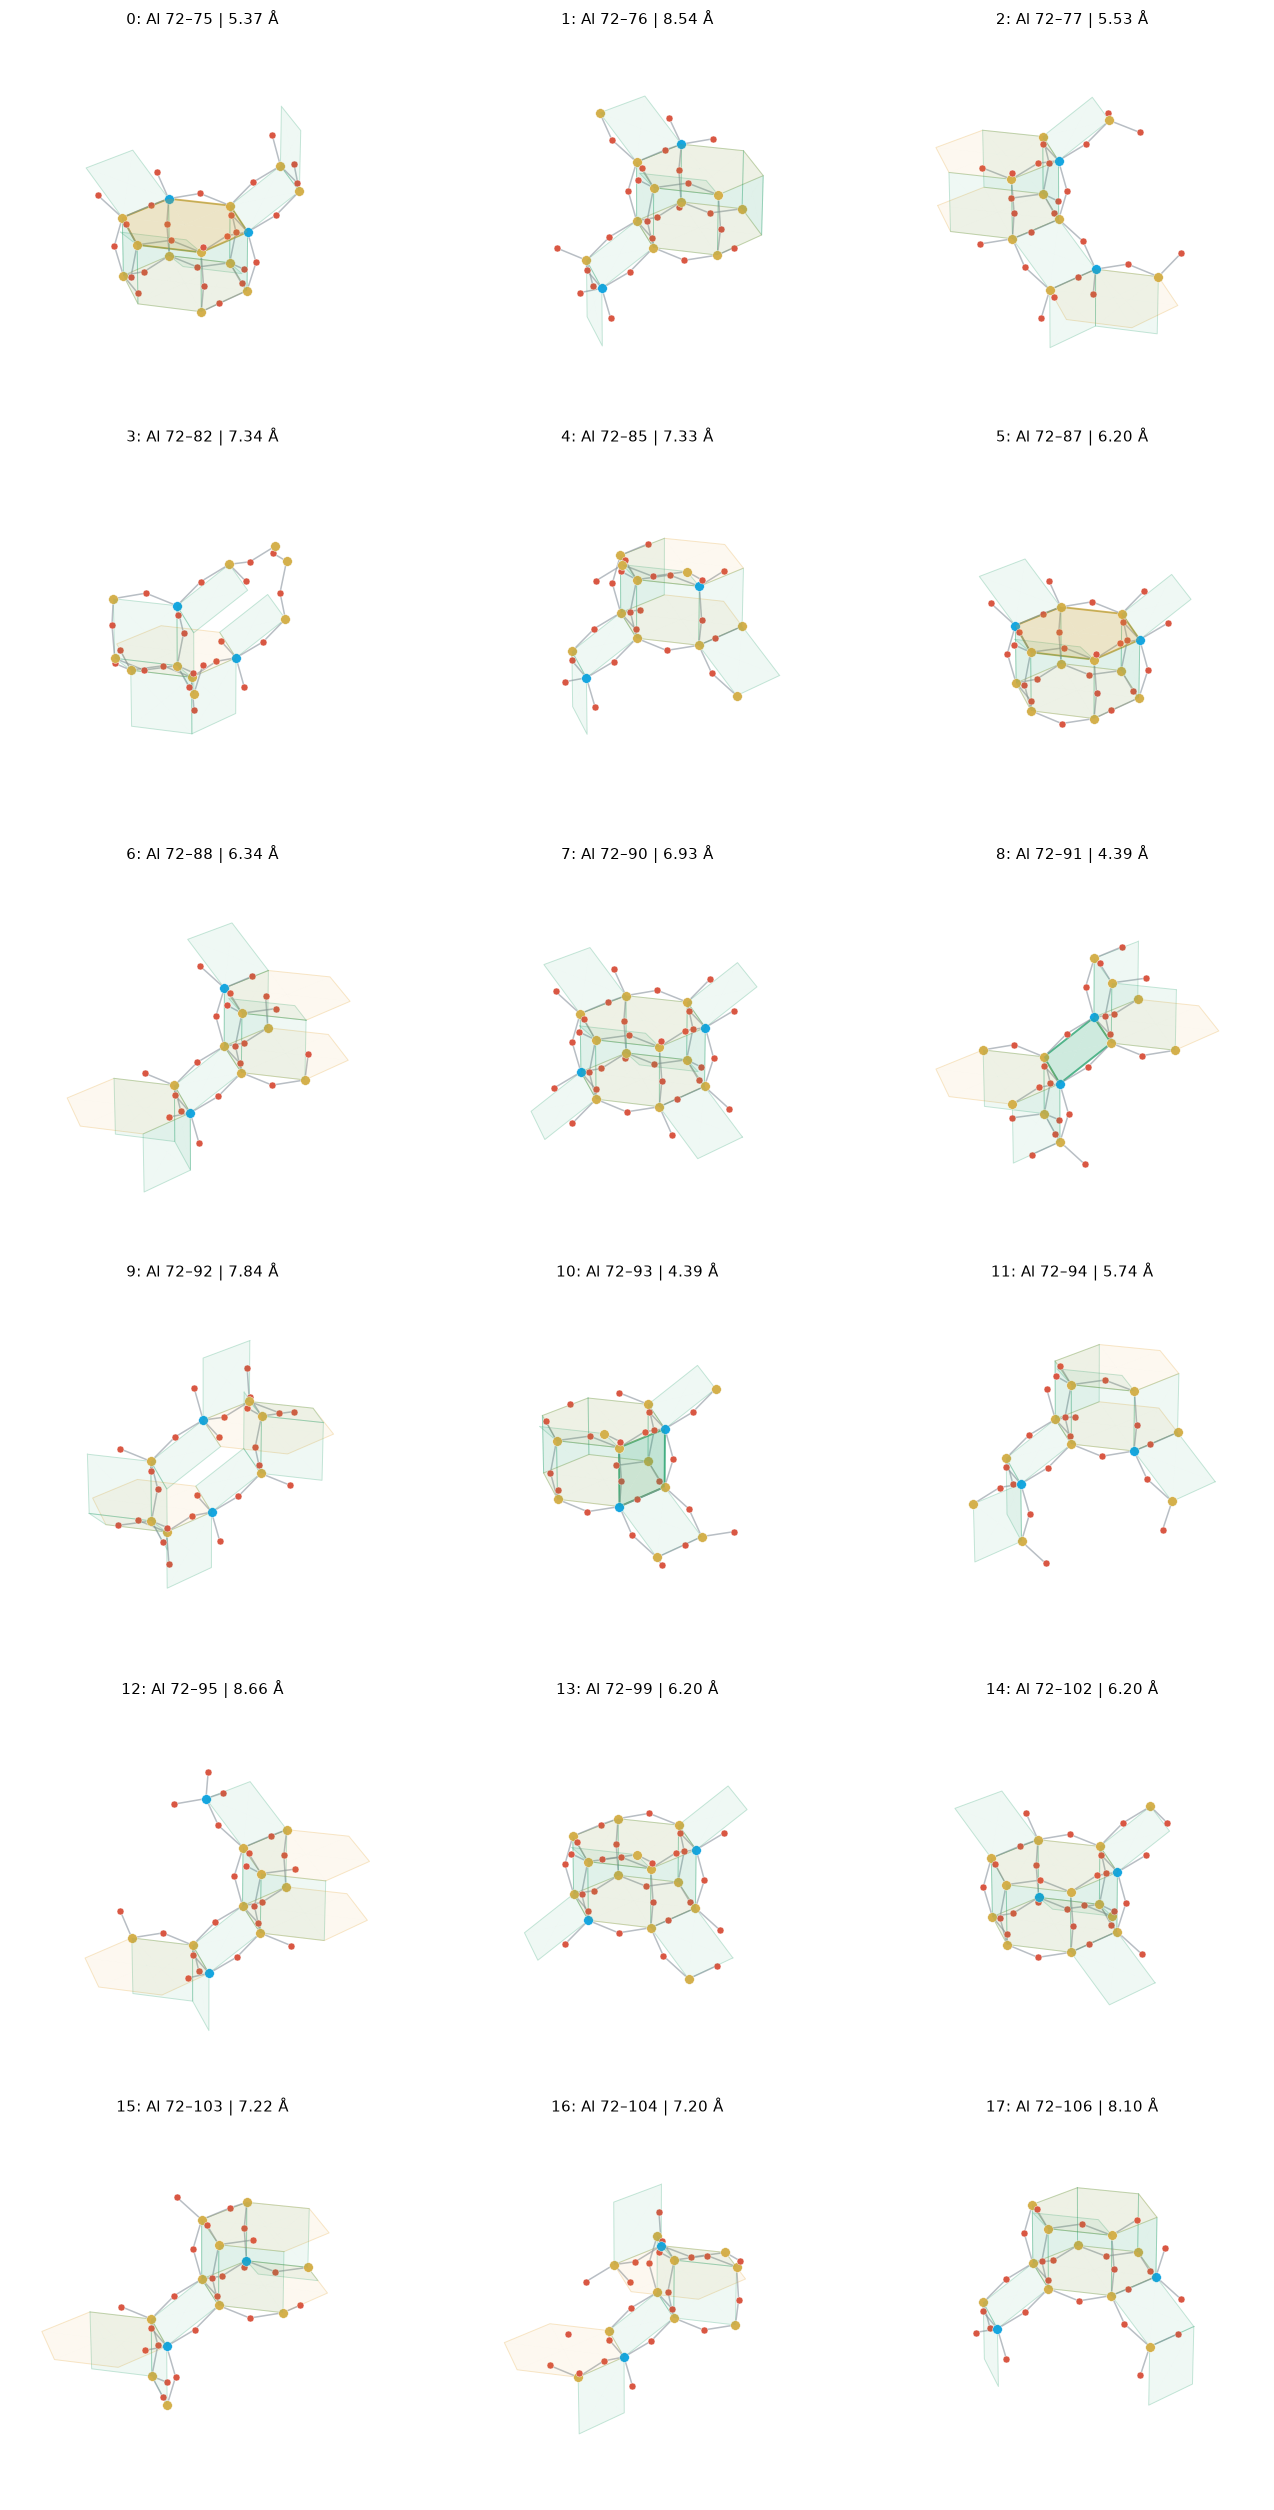

In [169]:

structures = []
centers = []
highlights = []
titles = []

for k, entry in enumerate(unique_pairs):
    i, j = entry["al_pair"]

    structures.append(substitute_al(framework, [i, j]))
    centers.append(pair_center(framework, i, j))
    highlights.append([i, j])

    distance = framework.get_distance(i, j, mic=True)
    titles.append(f"{k}: Al {i}–{j} | {distance:.2f} Å")

print(f"Structures: {len(structures)}")

fig = plot_structure_grid(
    structures,
    centers=centers,
    highlight_indices=highlights,
    titles=titles,
    radius=5.5,
    ncols=3,
    elev=25,
    azim=45,
    show_labels=False,
    ring_overlays=True
)

plt.show()


In [149]:

from scipy.spatial import cKDTree
from itertools import product
from ase.geometry import find_mic
from ase import Atom




cu_sites = [
    build_m2_structure(framework, pocket, metal="Cu")
    for result in all_pockets
    for pocket in result["pockets"][:1]
]

print("Generated Cu2+ structures:", len(cu_sites))



Generated Cu2+ structures: 1


In [150]:

all_pockets = []

for k, entry in enumerate(unique_pairs):
    pair = entry["al_pair"]

    pockets = find_m2_pockets(framework, pair, metal="Cu")

    all_pockets.append({
        "pair_id": k,
        "al_pair": pair,
        "al_distance_A": framework.get_distance(*pair, mic=True),
        "n_pockets": len(pockets),
        "best_score": min((p["score"] for p in pockets), default=np.nan),
        "pockets": pockets
    })

pocket_df = pd.DataFrame([
    {k: v for k, v in result.items() if k != "pockets"}
    for result in all_pockets
])
pocket_df

,pair_id,al_pair,al_distance_A,n_pockets,best_score
0,0,"(72, 75)",5.366020,0,NaN
1,1,"(72, 76)",8.538646,0,NaN
2,2,"(72, 77)",5.534121,0,NaN
3,3,"(72, 82)",7.337749,0,NaN
4,4,"(72, 85)",7.331474,0,NaN
5,5,"(72, 87)",6.196142,0,NaN
6,6,"(72, 88)",6.342279,0,NaN
7,7,"(72, 90)",6.930165,0,NaN
8,8,"(72, 91)",4.386951,2,0.564862
9,9,"(72, 92)",7.841401,0,NaN


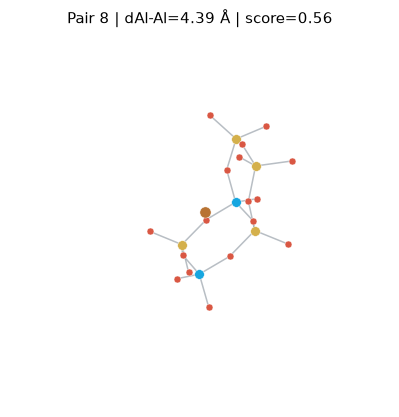

In [151]:

sites, highlights, titles, metal_indices = [], [], [], []

for result in all_pockets:
    if not result["pockets"]:
        continue

    site = build_m2_structure(framework, result["pockets"][0])

    sites.append(site)
    highlights.append(list(result["al_pair"]))
    metal_indices.append(len(site)-1)

    titles.append(
        f"Pair {result['pair_id']} | "
        f"dAl-Al={result['al_distance_A']:.2f} Å | "
        f"score={result['best_score']:.2f}"
    )

fig = plot_structure_grid(
    sites,
    center_indices=metal_indices,
    highlight_indices=highlights,
    titles=titles,
    radius=5,
    ncols=3,
    elev=25,
    azim=45
)

plt.show()


In [152]:

from zse import cation
from tqdm.auto import tqdm
import pandas as pd

cu2_sites = []
summary = []

for pair_id, entry in enumerate(tqdm(unique_pairs)):
    al_pair = tuple(map(int, entry["al_pair"]))
    al_framework = substitute_al(framework, al_pair)

    structures = cation.divalent(al_framework, "Cu")

    summary.append({
        "pair_id": pair_id,
        "al_pair": al_pair,
        "al_distance_A": framework.get_distance(*al_pair, mic=True),
        "n_structures": len(structures)
    })

    for position_id, atoms in enumerate(structures):
        cu2_sites.append({
            "pair_id": pair_id,
            "al_pair": al_pair,
            "position_id": position_id,
            "structure": atoms
        })

summary_df = pd.DataFrame(summary)

display(summary_df)
print("Total generated structures:", len(cu2_sites))


  0%|          | 0/18 [00:00<?, ?it/s]

,pair_id,al_pair,al_distance_A,n_structures
0,0,"(72, 75)",5.366020,12
1,1,"(72, 76)",8.538646,12
2,2,"(72, 77)",5.534121,12
3,3,"(72, 82)",7.337749,12
4,4,"(72, 85)",7.331474,12
5,5,"(72, 87)",6.196142,12
6,6,"(72, 88)",6.342279,12
7,7,"(72, 90)",6.930165,12
8,8,"(72, 91)",4.386951,12
9,9,"(72, 92)",7.841401,12


Total generated structures: 216


,pair_id,position_id,n_o,min_mo_A,min_mt_A,nearest_o_A
0,0,0,4,1.609262,1.859283,"[1.6092620201483314, 1.611363388496396, 2.0689..."
1,0,1,3,1.609262,1.858186,"[1.6092620201483316, 1.6096714640277328, 2.503..."
2,0,2,4,1.609262,1.854234,"[1.6092620201483314, 1.6094125342436718, 2.027..."
3,0,3,2,1.609671,1.863791,"[1.6096714640277328, 1.611363388496396, 3.0852..."
4,0,4,2,1.609413,1.862880,"[1.6094125342436723, 1.611363388496396, 3.0026..."
5,0,5,4,1.609413,1.855546,"[1.6094125342436723, 1.6096714640277328, 2.016..."
6,0,6,4,1.609262,1.859283,"[1.6092620201483332, 1.6113633884963983, 2.068..."
7,0,7,3,1.609262,1.858186,"[1.6092620201483336, 1.6096714640277345, 2.503..."
8,0,8,4,1.609262,1.854234,"[1.6092620201483332, 1.6094125342436727, 2.027..."
9,0,9,2,1.609671,1.863791,"[1.6096714640277345, 1.6113633884963983, 3.085..."


Coordination distribution:


n_o
2     72
3     36
4    108
Name: count, dtype: int64

Geometrically plausible candidates: 0


Series([], dtype: int64)

ZSE identified 27 4MRs and 6 6MRs


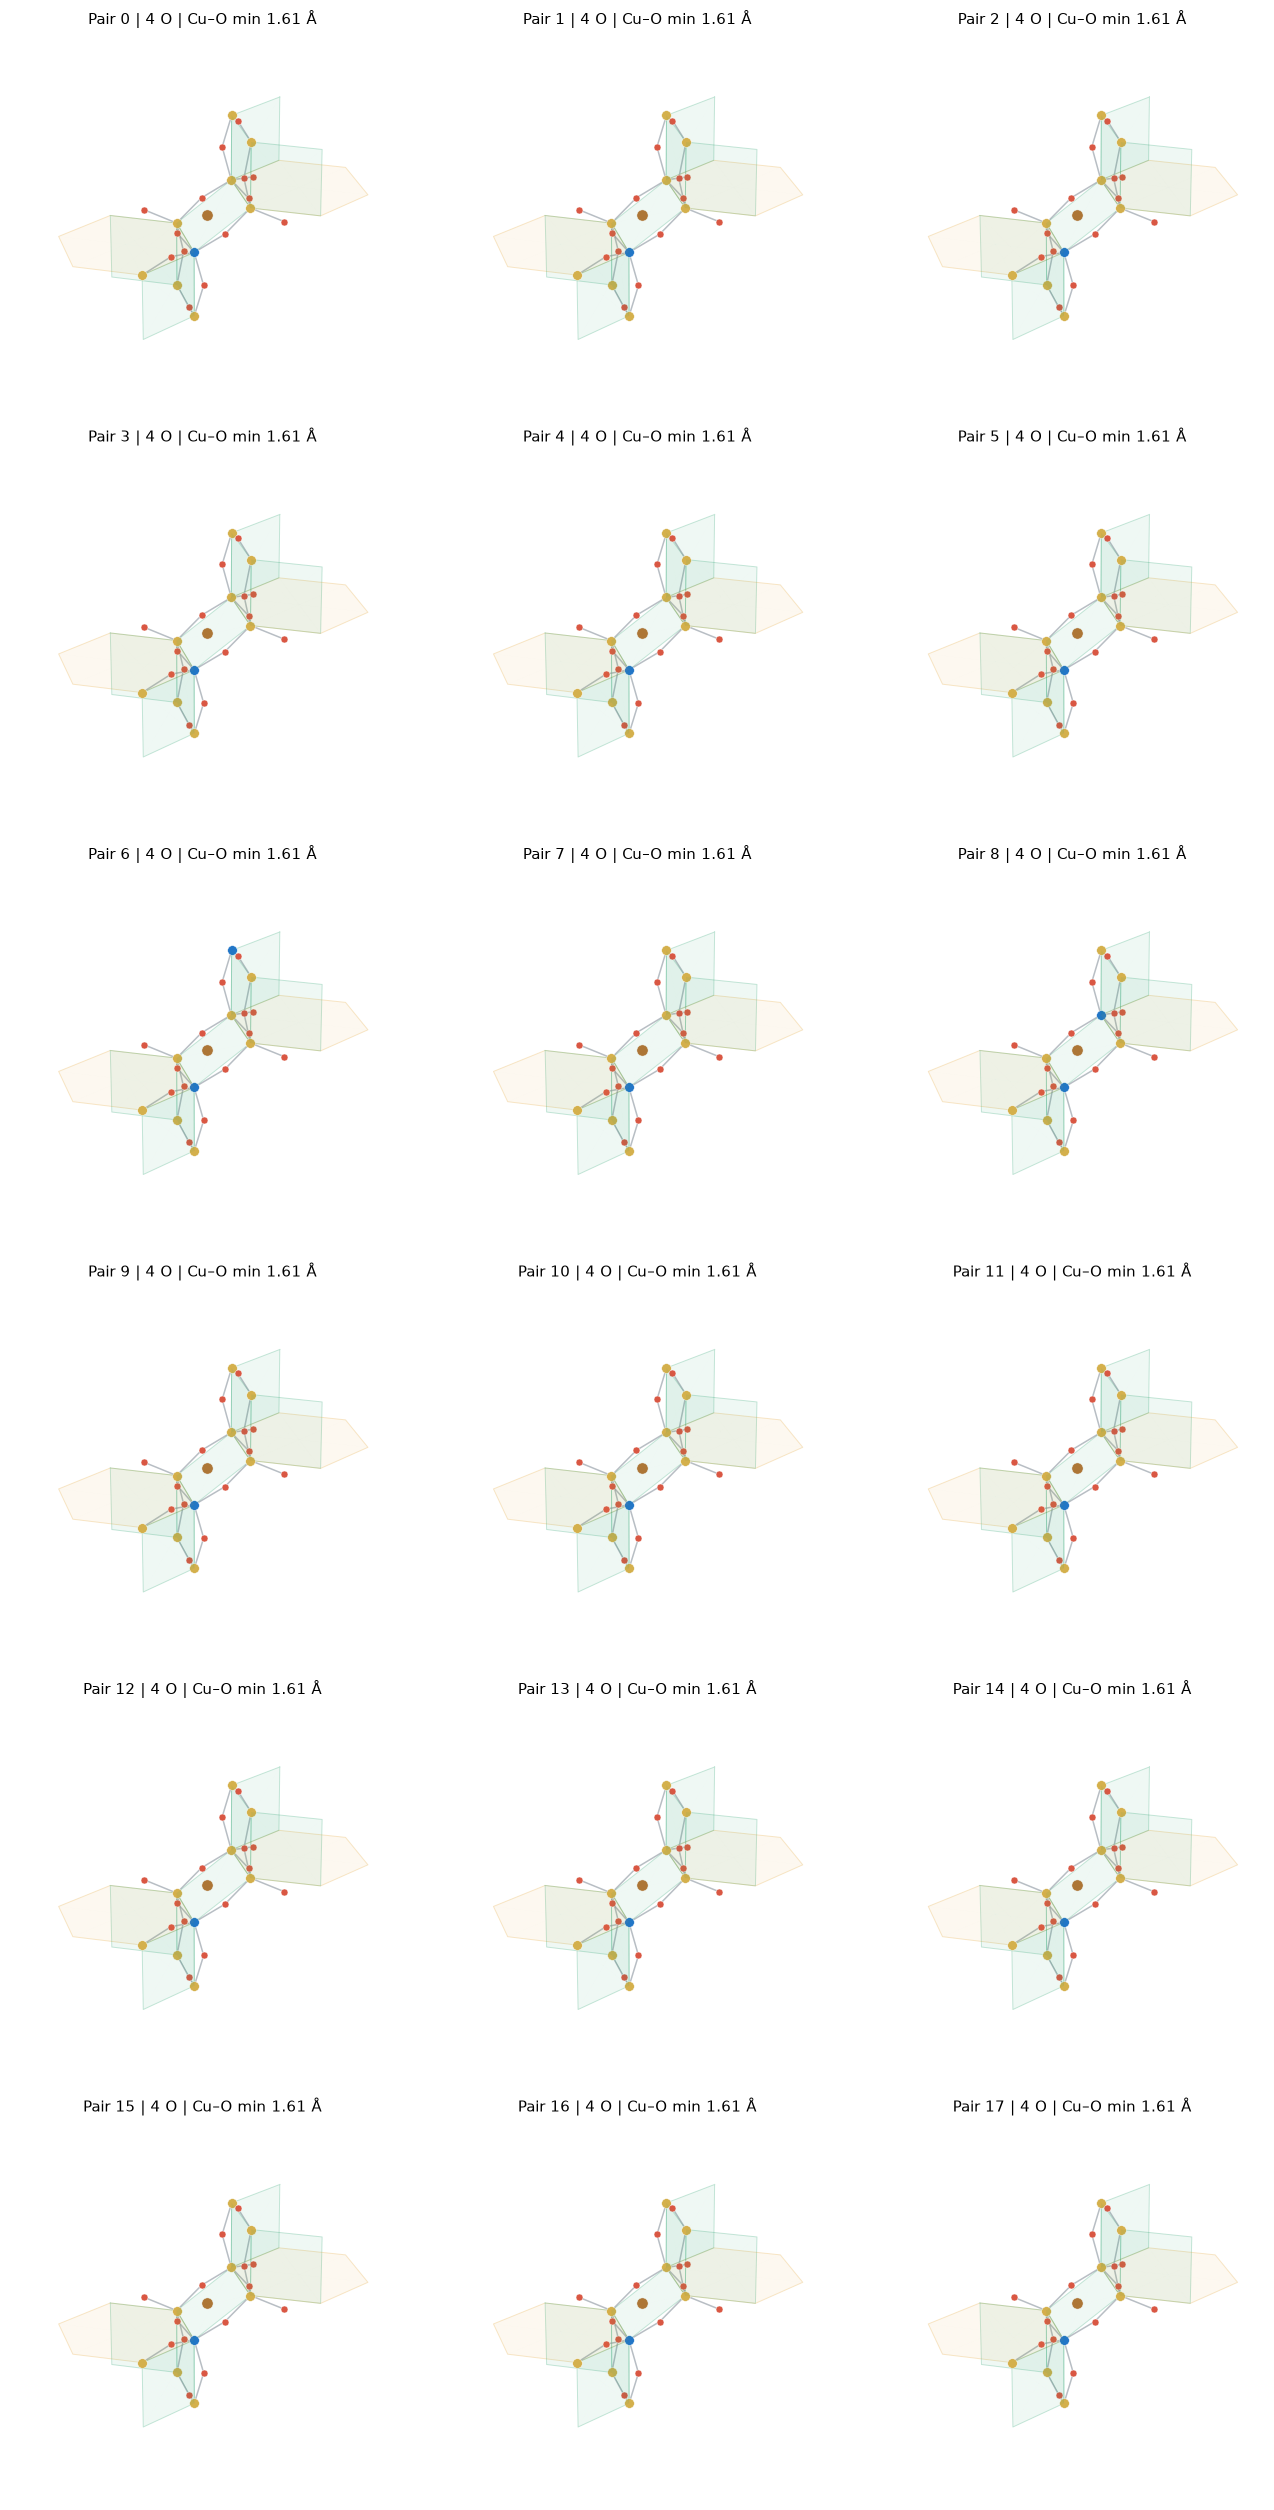

In [168]:

def describe_cation_site(atoms, metal="Cu", cutoff=2.7):
    metal_index = next(i for i, a in enumerate(atoms) if a.symbol == metal)
    oxygen_indices = [a.index for a in atoms if a.symbol == "O"]
    t_indices = [a.index for a in atoms if a.symbol in ("Si", "Al")]

    d_o = atoms.get_distances(metal_index, oxygen_indices, mic=True)
    d_t = atoms.get_distances(metal_index, t_indices, mic=True)

    return {
        "n_o": int((d_o < cutoff).sum()),
        "min_mo_A": float(d_o.min()),
        "min_mt_A": float(d_t.min()),
        "nearest_o_A": sorted(d_o)[:6]
    }


site_df = pd.DataFrame([
    {
        "pair_id": site["pair_id"],
        "position_id": site["position_id"],
        **describe_cation_site(site["structure"])
    }
    for site in cu2_sites
])

display(site_df.head(20))
print("Coordination distribution:")
display(site_df.n_o.value_counts().sort_index())

feasible = site_df[
    (site_df.n_o >= 4) &
    (site_df.min_mo_A > 1.7) &
    (site_df.min_mt_A > 2.3)
]

print("Geometrically plausible candidates:", len(feasible))
display(feasible.groupby("pair_id").size())


plot_sites, highlights, titles, centers = [], [], [], []

for pair_id in sorted(site_df.pair_id.unique()):
    subset = site_df[site_df.pair_id == pair_id].copy()
    subset["score"] = (
        abs(subset.n_o - 4)
        + 5 * (subset.min_mo_A < 1.7)
        + 5 * (subset.min_mt_A < 2.3)
    )

    best = subset.sort_values("score").iloc[0]

    site = next(
        s for s in cu2_sites
        if s["pair_id"] == pair_id and s["position_id"] == best.position_id
    )

    atoms = site["structure"]

    plot_sites.append(atoms)
    highlights.append(list(site["al_pair"]) + [len(atoms) - 1])
    centers.append(len(atoms) - 1)
    titles.append(
        f"Pair {pair_id} | {int(best.n_o)} O | "
        f"Cu–O min {best.min_mo_A:.2f} Å"
    )

fig = plot_structure_grid(
    plot_sites,
    center_indices=centers,
    highlight_indices=None,
    titles=titles,
    radius=5,
    ncols=3,
    ring_overlays=True
)

plt.show()


In [154]:

from ase.geometry import find_mic

def compare_zse_positions(sites, position_id=0):
    rows = []
    reference_pos = None

    for site in sites:
        if site["position_id"] != position_id:
            continue

        atoms = site["structure"]
        pair = site["al_pair"]
        cu_index = next(i for i, a in enumerate(atoms) if a.symbol == "Cu")
        pos = atoms.positions[cu_index]

        if reference_pos is None:
            reference_pos = pos.copy()

        _, distance = find_mic(pos - reference_pos, atoms.cell, atoms.pbc)

        rows.append({
            "pair_id": site["pair_id"],
            "al_pair": pair,
            "distance_from_reference_Cu_A": float(distance),
            "Cu_Al1_A": atoms.get_distance(cu_index, pair[0], mic=True),
            "Cu_Al2_A": atoms.get_distance(cu_index, pair[1], mic=True)
        })

    return pd.DataFrame(rows)


display(compare_zse_positions(cu2_sites))


,pair_id,al_pair,distance_from_reference_Cu_A,Cu_Al1_A,Cu_Al2_A
0,0,"(72, 75)",0.0,1.859283,5.156197
1,1,"(72, 76)",0.0,1.859283,6.706298
2,2,"(72, 77)",0.0,1.859283,6.949218
3,3,"(72, 82)",0.0,1.859283,7.833507
4,4,"(72, 85)",0.0,1.859283,6.311196
5,5,"(72, 87)",0.0,1.859283,6.670925
6,6,"(72, 88)",0.0,1.859283,4.539531
7,7,"(72, 90)",0.0,1.859283,7.836910
8,8,"(72, 91)",0.0,1.859283,2.628514
9,9,"(72, 92)",0.0,1.859283,7.759452


In [155]:



coord_df = pd.DataFrame([
    {
        "pair_id": s["pair_id"],
        "position_id": s["position_id"],
        **describe_shared_coordination(s["structure"], s["al_pair"])
    }
    for s in cu2_sites
])

display(coord_df.groupby("pair_id").agg(
    max_o_al1=("n_o_al1", "max"),
    max_o_al2=("n_o_al2", "max"),
    n_four_shared=("four_shared_o", "sum")
))


,max_o_al1,max_o_al2,n_four_shared
pair_id,,,
0,2,2,0
1,2,2,0
2,2,2,0
3,2,2,0
4,2,2,0
5,2,2,0
6,2,2,0
7,2,2,0
8,2,2,2


In [156]:
for pair_id in [8, 10]:
    pair = unique_pairs[pair_id]["al_pair"]

    for radius in [3.0, 4.0, 5.0]:
        pockets = find_m2_pockets(
            framework,
            pair,
            metal="Cu",
            search_radius=radius,
            spacing=0.25,
            n_sites=10
        )

        print(
            f"Pair {pair_id}, radius {radius:.1f} Å: "
            f"{len(pockets)} pockets, "
            f"best score = {min((p['score'] for p in pockets), default=np.nan):.3f}"
        )

Pair 8, radius 3.0 Å: 2 pockets, best score = 0.379
Pair 8, radius 4.0 Å: 2 pockets, best score = 0.379
Pair 8, radius 5.0 Å: 2 pockets, best score = 0.379
Pair 10, radius 3.0 Å: 2 pockets, best score = 0.115
Pair 10, radius 4.0 Å: 2 pockets, best score = 0.115
Pair 10, radius 5.0 Å: 2 pockets, best score = 0.115


ZSE identified 27 4MRs and 6 6MRs


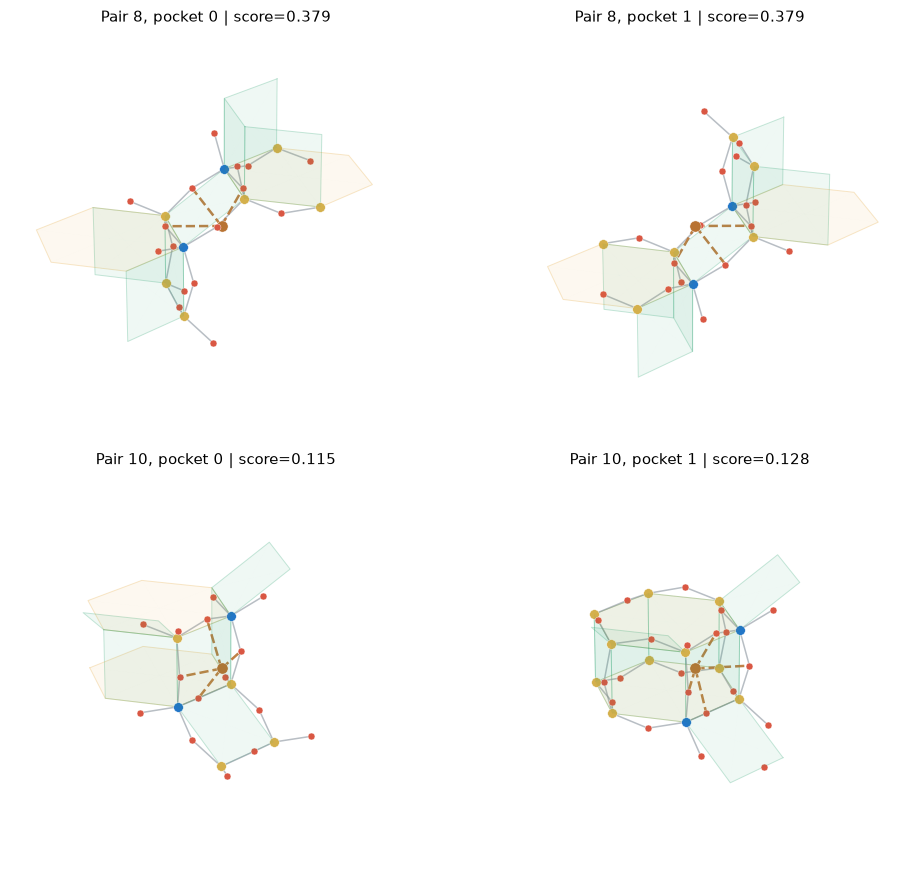

In [166]:

selected_pairs = [8, 10]

sites, centers, highlights, titles = [], [], [], []

for pair_id in selected_pairs:
    pair = unique_pairs[pair_id]["al_pair"]

    pockets = find_m2_pockets(
        framework, pair, metal="Cu",
        search_radius=3.0, spacing=0.25,
        n_sites=10
    )

    for pocket_id, pocket in enumerate(pockets):
        atoms = build_m2_structure(framework, pocket, metal="Cu")

        sites.append(atoms)
        centers.append(len(atoms) - 1)
        highlights.append(list(pair) + [len(atoms) - 1])
        titles.append(
            f"Pair {pair_id}, pocket {pocket_id} | "
            f"score={pocket['score']:.3f}"
        )

fig = plot_structure_grid(
    sites,
    center_indices=centers,
    cation_indices=centers,
    highlight_indices=None,
    titles=titles,
    radius=5,
    ncols=2,
    figsize=(10, 9),
    elev=25,
    azim=45,
    coord_cutoff=2.7,
    ring_overlays=True
)


In [162]:

import io
import contextlib
from zse.rings import get_rings

def check_pair_rings(framework, pair_ids=(8, 10)):
    n = len(framework)

    for pair_id in pair_ids:
        i, j = unique_pairs[pair_id]["al_pair"]

        with contextlib.redirect_stdout(io.StringIO()):
            sizes, paths, _, repeated = get_rings(
                framework, index=int(i), max_ring=8, validation="goetzke"
            )

        symbols = np.array(repeated.get_chemical_symbols())
        shared = []

        for size, path in zip(sizes, paths):
            if int(size) not in (4, 6, 8):
                continue

            path = np.asarray(path, dtype=int)
            t_path = path[np.isin(symbols[path], ["Si", "Al"])]
            t_indices = (t_path % n).tolist()

            if i in t_indices and j in t_indices:
                shared.append((int(size), t_indices))

        print(f"\nPair {pair_id}: Al {i}, {j}")
        print(f"Al–Al distance: {framework.get_distance(i, j, mic=True):.3f} Å")

        if shared:
            for size, indices in sorted(shared):
                print(f"  Shared {size}MR: {indices}")
        else:
            print("  No shared 4MR, 6MR or 8MR found")

check_pair_rings(framework)



Pair 8: Al 72, 91
Al–Al distance: 4.387 Å
  Shared 4MR: [72, 81, 91, 100]

Pair 10: Al 72, 93
Al–Al distance: 4.386 Å
  Shared 4MR: [72, 105, 93, 84]
  Shared 8MR: [72, 84, 93, 99, 90, 102, 75, 81]
  Shared 8MR: [72, 105, 93, 99, 90, 87, 75, 81]


In [170]:

import io
import contextlib
import numpy as np
import pandas as pd
from zse.rings import get_rings
from ase.geometry import find_mic

def rings_around_t(framework, t_index, sizes=(4, 6)):
    with contextlib.redirect_stdout(io.StringIO()):
        ring_sizes, paths, _, repeated = get_rings(
            framework, index=int(t_index),
            max_ring=max(sizes), validation="goetzke"
        )

    rings = []
    seen = set()
    n = len(framework)
    symbols = np.asarray(framework.get_chemical_symbols())

    for size, path in zip(ring_sizes, paths):
        size = int(size)
        if size not in sizes:
            continue

        ids = np.asarray(path, dtype=int) % n
        if len(ids) != 2 * size:
            continue

        is_t = np.isin(symbols[ids], ["Si", "Al"])
        if is_t.sum() != size or np.any(is_t == np.roll(is_t, 1)):
            continue

        # Unwrap the complete T-O-T path
        coords = [framework.positions[ids[0]].copy()]
        valid = True

        for a, b in zip(ids[:-1], ids[1:]):
            vec = framework.get_distance(int(a), int(b), mic=True, vector=True)
            if np.linalg.norm(vec) > 2.1:
                valid = False
                break
            coords.append(coords[-1] + vec)

        if not valid:
            continue

        coords = np.asarray(coords)

        # Check periodic ring closure
        closing = framework.get_distance(int(ids[-1]), int(ids[0]), mic=True, vector=True)
        if np.linalg.norm(coords[-1] + closing - coords[0]) > 0.2:
            continue

        t_ids = ids[is_t].tolist()
        o_ids = ids[~is_t].tolist()
        key = (size, tuple(sorted(t_ids)), tuple(sorted(o_ids)))

        if key in seen:
            continue
        seen.add(key)

        rings.append({
            "size": size,
            "t_indices": t_ids,
            "o_indices": o_ids,
            "t_coords": coords[is_t],
            "o_coords": coords[~is_t]
        })

    return rings


reference_t = unique_pairs[0]["al_pair"][0]
local_rings = rings_around_t(framework, reference_t)

print("4MRs:", sum(r["size"] == 4 for r in local_rings))
print("6MRs:", sum(r["size"] == 6 for r in local_rings))


4MRs: 3
6MRs: 1


In [181]:

import contextlib
import io
from dataclasses import dataclass
from itertools import combinations
from scipy.optimize import minimize
import numpy as np
import pandas as pd
import spglib
from ase import Atom, Atoms
from ase.geometry import find_mic
from zse.rings import get_rings


@dataclass
class ExchangeSite:
    atoms: Atoms
    metal: str
    al_indices: tuple
    ring_size: int
    ring_t_indices: tuple
    ring_o_indices: tuple
    ring_center: np.ndarray
    metal_position: np.ndarray
    diagnostics: dict
    multiplicity: int


class ExtraFrameworkStructureGenerator:
    """Shared functionality for generating extraframework zeolite species."""

    def __init__(self, framework, ring_sizes=(4, 6, 8),
                 bond_cutoff=2.1, symprec=0.01):

        self.framework = framework.copy()
        self.framework.pbc = True
        self.ring_sizes = tuple(sorted(set(map(int, ring_sizes))))
        self.bond_cutoff = float(bond_cutoff)
        self.symprec = float(symprec)

        self._rings = None
        self._symmetry_maps = None
        self._neighbors = None

    @property
    def t_indices(self):
        return tuple(a.index for a in self.framework
                     if a.symbol in ("Si", "Al"))

    @property
    def si_indices(self):
        return tuple(a.index for a in self.framework if a.symbol == "Si")


    @property
    def t_o_neighbors(self):
        if self._neighbors is None:
            oxygens = np.array([a.index for a in self.framework
                                if a.symbol == "O"])

            self._neighbors = {}

            for i in self.t_indices:
                distances = self.framework.get_distances(i, oxygens, mic=True)
                self._neighbors[i] = set(map(
                    int, oxygens[distances < self.bond_cutoff]
                ))

        return self._neighbors

    def substitute_al(self, indices):
        atoms = self.framework.copy()

        for i in indices:
            if atoms[int(i)].symbol != "Si":
                raise ValueError(f"T-site {i} is not Si")
            atoms[int(i)].symbol = "Al"

        return atoms


    def obeys_lowenstein(self, pair):
        i, j = map(int, pair)
        return i != j and not (
            self.t_o_neighbors[i] & self.t_o_neighbors[j]
        )

    @property
    def symmetry_maps(self):
        """Map T-site indices under parent-framework symmetry operations."""

        if self._symmetry_maps is None:
            atoms = self.framework
            scaled = atoms.get_scaled_positions(wrap=True)
            cell = np.asarray(atoms.cell)
            numbers = atoms.get_atomic_numbers()

            symmetry = spglib.get_symmetry(
                (cell, scaled, numbers), symprec=self.symprec
            )

            if symmetry is None:
                raise RuntimeError("Could not determine framework symmetry")

            t_indices = np.array(self.t_indices)
            positions = atoms.positions[t_indices]
            maps = []

            for rotation, translation in zip(
                symmetry["rotations"], symmetry["translations"]
            ):
                transformed = (scaled[t_indices] @ rotation.T + translation) @ cell
                mapping = {}

                for old, pos in zip(t_indices, transformed):
                    _, distances = find_mic(
                        positions - pos, atoms.cell, atoms.pbc
                    )

                    nearest = int(np.argmin(distances))

                    if distances[nearest] > 0.1:
                        raise RuntimeError("Symmetry mapping failed")

                    mapping[int(old)] = int(t_indices[nearest])

                if len(set(mapping.values())) != len(t_indices):
                    raise RuntimeError("Invalid symmetry permutation")

                maps.append(mapping)

            self._symmetry_maps = maps

        return self._symmetry_maps


    def unique_pairs(self, pairs):
        """Reduce eligible Al pairs using parent-framework symmetry."""

        eligible = {tuple(sorted(map(int, p))) for p in pairs}
        remaining = eligible.copy()
        unique = []

        while remaining:
            pair = min(remaining)

            equivalents = {
                tuple(sorted((perm[pair[0]], perm[pair[1]])))
                for perm in self.symmetry_maps
            }

            matches = equivalents & eligible
            unique.append((pair, len(matches)))
            remaining.difference_update(matches)

        return unique


    def _read_rings_around_t(self, t_index):
        """Find ZSE rings and reconstruct continuous periodic ring geometry."""

        with contextlib.redirect_stdout(io.StringIO()):
            sizes, paths, _, repeated = get_rings(
                self.framework,
                index=int(t_index),
                max_ring=max(self.ring_sizes),
                validation="goetzke"
            )

        atoms = self.framework
        n = len(atoms)
        symbols = np.asarray(atoms.get_chemical_symbols())
        repeated_symbols = np.asarray(repeated.get_chemical_symbols())
        rings = []

        for size, path in zip(sizes, paths):
            size = int(size)

            if size not in self.ring_sizes:
                continue

            path = np.asarray(path, dtype=int)

            if len(path) != 2 * size:
                continue

            if path.min() < 0 or path.max() >= len(repeated):
                continue

            indices = path % n

            if not np.array_equal(repeated_symbols[path], symbols[indices]):
                continue

            is_t = np.isin(symbols[indices], ("Si", "Al"))

            if is_t.sum() != size or np.any(is_t == np.roll(is_t, 1)):
                continue

            if len(set(indices[is_t])) != size:
                continue

            if len(set(indices[~is_t])) != size:
                continue

            # Unwrap consecutive T-O bonds using minimum-image vectors
            coords = [atoms.positions[indices[0]].copy()]
            valid = True

            for i, j in zip(indices[:-1], indices[1:]):
                vector = atoms.get_distance(
                    int(i), int(j), mic=True, vector=True
                )

                if np.linalg.norm(vector) > self.bond_cutoff:
                    valid = False
                    break

                coords.append(coords[-1] + vector)

            if not valid:
                continue

            coords = np.asarray(coords)

            # Verify that the ring closes without periodic winding
            closing = atoms.get_distance(
                int(indices[-1]), int(indices[0]),
                mic=True, vector=True
            )

            if np.linalg.norm(closing) > self.bond_cutoff:
                continue

            if np.linalg.norm(coords[-1] + closing - coords[0]) > 0.2:
                continue

            o_coords = coords[~is_t]
            center = o_coords.mean(axis=0)

            _, _, vh = np.linalg.svd(o_coords - center)
            normal = vh[-1]
            normal /= np.linalg.norm(normal)

            rings.append({
                "size": size,
                "t_indices": tuple(map(int, indices[is_t])),
                "o_indices": tuple(map(int, indices[~is_t])),
                "o_coords": o_coords,
                "center": center,
                "normal": normal
            })

        return rings


    @property
    def rings(self):
        """Cached catalogue of distinct framework rings."""

        if self._rings is None:
            ring_map = {}

            for t in self.t_indices:
                for ring in self._read_rings_around_t(t):
                    key = (
                        ring["size"],
                        frozenset(ring["t_indices"]),
                        frozenset(ring["o_indices"])
                    )

                    ring_map.setdefault(key, ring)

            self._rings = list(ring_map.values())

        return self._rings


    def geometry(self, atoms, metal_index, cutoff=2.7):
        """Calculate initial metal-framework coordination diagnostics."""

        oxygens = [a.index for a in atoms if a.symbol == "O"]
        t_indices = [a.index for a in atoms
                     if a.symbol in ("Si", "Al")]

        d_o = atoms.get_distances(metal_index, oxygens, mic=True)
        d_t = atoms.get_distances(metal_index, t_indices, mic=True)

        nearest = sorted(zip(d_o, oxygens))[:6]

        return {
            "coordination_count": int(np.count_nonzero(d_o <= cutoff)),
            "min_mo_A": float(d_o.min()),
            "min_mt_A": float(d_t.min()),
            "nearest_oxygen_indices": [int(j) for _, j in nearest],
            "nearest_mo_A": [round(float(d), 3) for d, _ in nearest]
        }


    def place_atom(self, atoms, symbol, position):
        structure = atoms.copy()
        structure.append(Atom(symbol, position=np.asarray(position, dtype=float)))
        structure.wrap()
        return structure



class M2PlusGenerator(ExtraFrameworkStructureGenerator):
    """Generate charge-balanced Z2M2+ structures from two Al substitutions."""

    def __init__(self, framework, metal="Cu", ring_sizes=(4, 6, 8),
                 bond_cutoff=2.1, symprec=0.01, offset=0.15,
                 coordination_cutoff=2.7):

        super().__init__(
            framework,
            ring_sizes=ring_sizes,
            bond_cutoff=bond_cutoff,
            symprec=symprec
        )

        self.metal = metal
        self.offset = float(offset)
        self.coordination_cutoff = float(coordination_cutoff)


    def candidate_pairs(self, max_al_distance=None):
        """Find symmetry-distinct, nonadjacent Al pairs sharing a ring."""

        pairs = set()
        si_indices = set(self.si_indices)

        for ring in self.rings:
            for pair in combinations(sorted(ring["t_indices"]), 2):
                if not all(i in si_indices for i in pair):
                    continue

                if not self.obeys_lowenstein(pair):
                    continue

                if max_al_distance is not None:
                    distance = self.framework.get_distance(*pair, mic=True)
                    if distance > max_al_distance:
                        continue

                pairs.add(pair)

        return self.unique_pairs(pairs)

    def _make_site(self, pair, ring, multiplicity):
        atoms = self.substitute_al(pair)
        o_indices = np.array([a.index for a in atoms if a.symbol == "O"])
        t_indices = np.array([a.index for a in atoms if a.symbol in ("Si", "Al")])

        o_groups = [
            sorted(self.t_o_neighbors[int(i)])
            for i in pair
        ]

        centre = ring["center"]
        normal = ring["normal"]
        target_mo = 2.05  # Initial Cu-O target; make metal-dependent later

        def distances(pos, indices):
            vectors, _ = find_mic(atoms.positions[indices] - pos, atoms.cell, atoms.pbc)
            return np.linalg.norm(vectors, axis=1)

        def score(pos):
            d_o = np.sort(distances(pos, o_indices))
            d_t = distances(pos, t_indices)
            d_al = [np.sort(distances(pos, group)) for group in o_groups]

            # Favour four nearby framework oxygens
            coordination = np.sum((d_o[:4] - target_mo)**2)

            # Encourage coordination with both Al environments
            al_coordination = sum(
                2.0 * (d[0] - target_mo)**2
                + 0.5 * (d[1] - target_mo)**2
                for d in d_al
            )

            # Penalise very short framework contacts
            repulsion = (
                15 * np.sum(np.maximum(1.8 - d_o, 0)**2)
                + 20 * np.sum(np.maximum(2.4 - d_t, 0)**2)
            )

            # Keep the cation associated with the selected ring
            displacement = pos - centre
            height = np.dot(displacement, normal)
            lateral = np.linalg.norm(displacement - height * normal)

            confinement = (
                0.3 * max(lateral - ring["size"] * 0.35, 0)**2
                + 0.3 * max(abs(height) - 1.5, 0)**2
            )

            return coordination + al_coordination + repulsion + confinement

        # Initial seeds: ring centre and midpoints of Al-associated O pairs
        seeds = [centre + sign * 0.3 * normal for sign in (-1, 0, 1)]

        for o1 in o_groups[0]:
            for o2 in o_groups[1]:
                midpoint = atoms.positions[o1] + 0.5 * atoms.get_distance(
                    o1, o2, mic=True, vector=True
                )

                for sign in (-1, 0, 1):
                    seeds.append(midpoint + sign * 0.3 * normal)

        # Optimise the most promising seeds
        seeds = sorted(seeds, key=score)[:12]

        bounds = [(centre[i] - 4.0, centre[i] + 4.0) for i in range(3)]

        results = [
            minimize(score, seed, method="L-BFGS-B", bounds=bounds)
            for seed in seeds
        ]

        # Choose best converged geometry
        valid = [r for r in results if r.success and np.isfinite(r.fun)]
        best = min(valid or results, key=lambda r: r.fun)

        structure = self.place_atom(atoms, self.metal, best.x)
        diagnostics = self.geometry(
            structure, len(structure) - 1, self.coordination_cutoff
        )

        diagnostics["placement_score"] = float(best.fun)
        diagnostics["optimizer_success"] = bool(best.success)
        diagnostics["al_al_A"] = float(atoms.get_distance(*pair, mic=True))
        diagnostics["potential_clash"] = (
            diagnostics["min_mo_A"] < 1.8
            or diagnostics["min_mt_A"] < 2.4
        )

        return ExchangeSite(
            atoms=structure,
            metal=self.metal,
            al_indices=tuple(pair),
            ring_size=ring["size"],
            ring_t_indices=ring["t_indices"],
            ring_o_indices=ring["o_indices"],
            ring_center=centre.copy(),
            metal_position=structure.positions[-1].copy(),
            diagnostics=diagnostics,
            multiplicity=multiplicity
        )


    def deduplicate_sites(self, sites, tolerance=0.5):
        """Remove sites with the same Al pair and similar periodic metal positions."""
        unique = []

        for site in sorted(
            sites,
            key=lambda s: (
                s.diagnostics["potential_clash"],
                s.diagnostics.get("placement_score", np.inf)
            )
        ):
            duplicate = None

            for existing in unique:
                if site.al_indices != existing.al_indices:
                    continue

                vector, distance = find_mic(
                    site.metal_position - existing.metal_position,
                    self.framework.cell,
                    self.framework.pbc
                )

                if float(distance) < tolerance:
                    duplicate = existing
                    break

            if duplicate is None:
                unique.append(site)

        return unique


    def generate(self, max_al_distance=None, one_per_pair_ring=True):
        """Generate unrelaxed M2+ structures.

        Default: one site per symmetry-distinct Al pair and ring size.
        Multiple rings containing the same pair can be retained by setting
        one_per_pair_ring=False.
        """

        sites = []

        for pair, multiplicity in self.candidate_pairs(max_al_distance):
            for size in self.ring_sizes:
                matching_rings = [
                    ring for ring in self.rings
                    if ring["size"] == size
                    and set(pair).issubset(ring["t_indices"])
                ]

                if not matching_rings:
                    continue

                candidates = [
                    self._make_site(pair, ring, multiplicity)
                    for ring in matching_rings
                ]

                if one_per_pair_ring:
                    candidates.sort(key=lambda s: (
                        s.diagnostics["potential_clash"],
                        max(1.7 - s.diagnostics["min_mo_A"], 0)**2
                        + 4 * max(2.3 - s.diagnostics["min_mt_A"], 0)**2,
                        -s.diagnostics["coordination_count"]
                    ))
                    candidates = candidates[:1]

                sites.extend(candidates)

        return self.deduplicate_sites(sites)


    @staticmethod
    def summary(sites):
        return pd.DataFrame([
            {
                "metal": s.metal,
                "al_pair": s.al_indices,
                "ring_size": s.ring_size,
                "multiplicity": s.multiplicity,
                **{
                    k: v for k, v in s.diagnostics.items()
                    if k not in ("nearest_oxygen_indices", "nearest_mo_A")
                }
            }
            for s in sites
        ])


In [182]:

generator = M2PlusGenerator(
    framework,
    metal="Cu",
    ring_sizes=(4, 6, 8),
    offset=0.15
)

sites = generator.generate()
df = generator.summary(sites)

print(f"Identified {len(generator.rings)} framework rings")
print(f"Found {len(generator.candidate_pairs())} unique Al pairs")
print(f"Generated {len(sites)} Cu²⁺ structures")

display(df)
display(df.groupby("ring_size").size())


Identified 60 framework rings
Found 12 unique Al pairs
Generated 12 Cu²⁺ structures


,metal,al_pair,ring_size,multiplicity,coordination_count,min_mo_A,min_mt_A,placement_score,optimizer_success,al_al_A,potential_clash
0,Cu,"(72, 75)",8,36,4,2.103552,2.774838,1.235892,True,5.366020,False
1,Cu,"(72, 87)",6,18,4,2.218840,2.924483,1.588722,True,6.196142,False
2,Cu,"(72, 104)",8,18,2,1.866587,2.673313,6.205413,True,7.200788,False
3,Cu,"(72, 90)",8,18,4,1.979696,2.491904,6.492074,True,6.930165,False
4,Cu,"(72, 92)",8,18,2,2.328054,3.015916,10.034856,True,7.841401,False
5,Cu,"(72, 93)",8,36,4,1.924134,2.371553,0.212296,True,4.385547,True
6,Cu,"(72, 91)",4,18,4,1.934082,2.375455,0.235675,True,4.386951,True
7,Cu,"(72, 77)",8,36,4,2.252840,2.329793,1.731936,True,5.534121,True
8,Cu,"(72, 102)",8,18,4,2.214617,2.347698,1.739115,True,6.196046,True
9,Cu,"(72, 94)",8,36,3,2.055143,2.358553,2.940182,True,5.735978,True


ring_size
4     1
6     1
8    10
dtype: int64

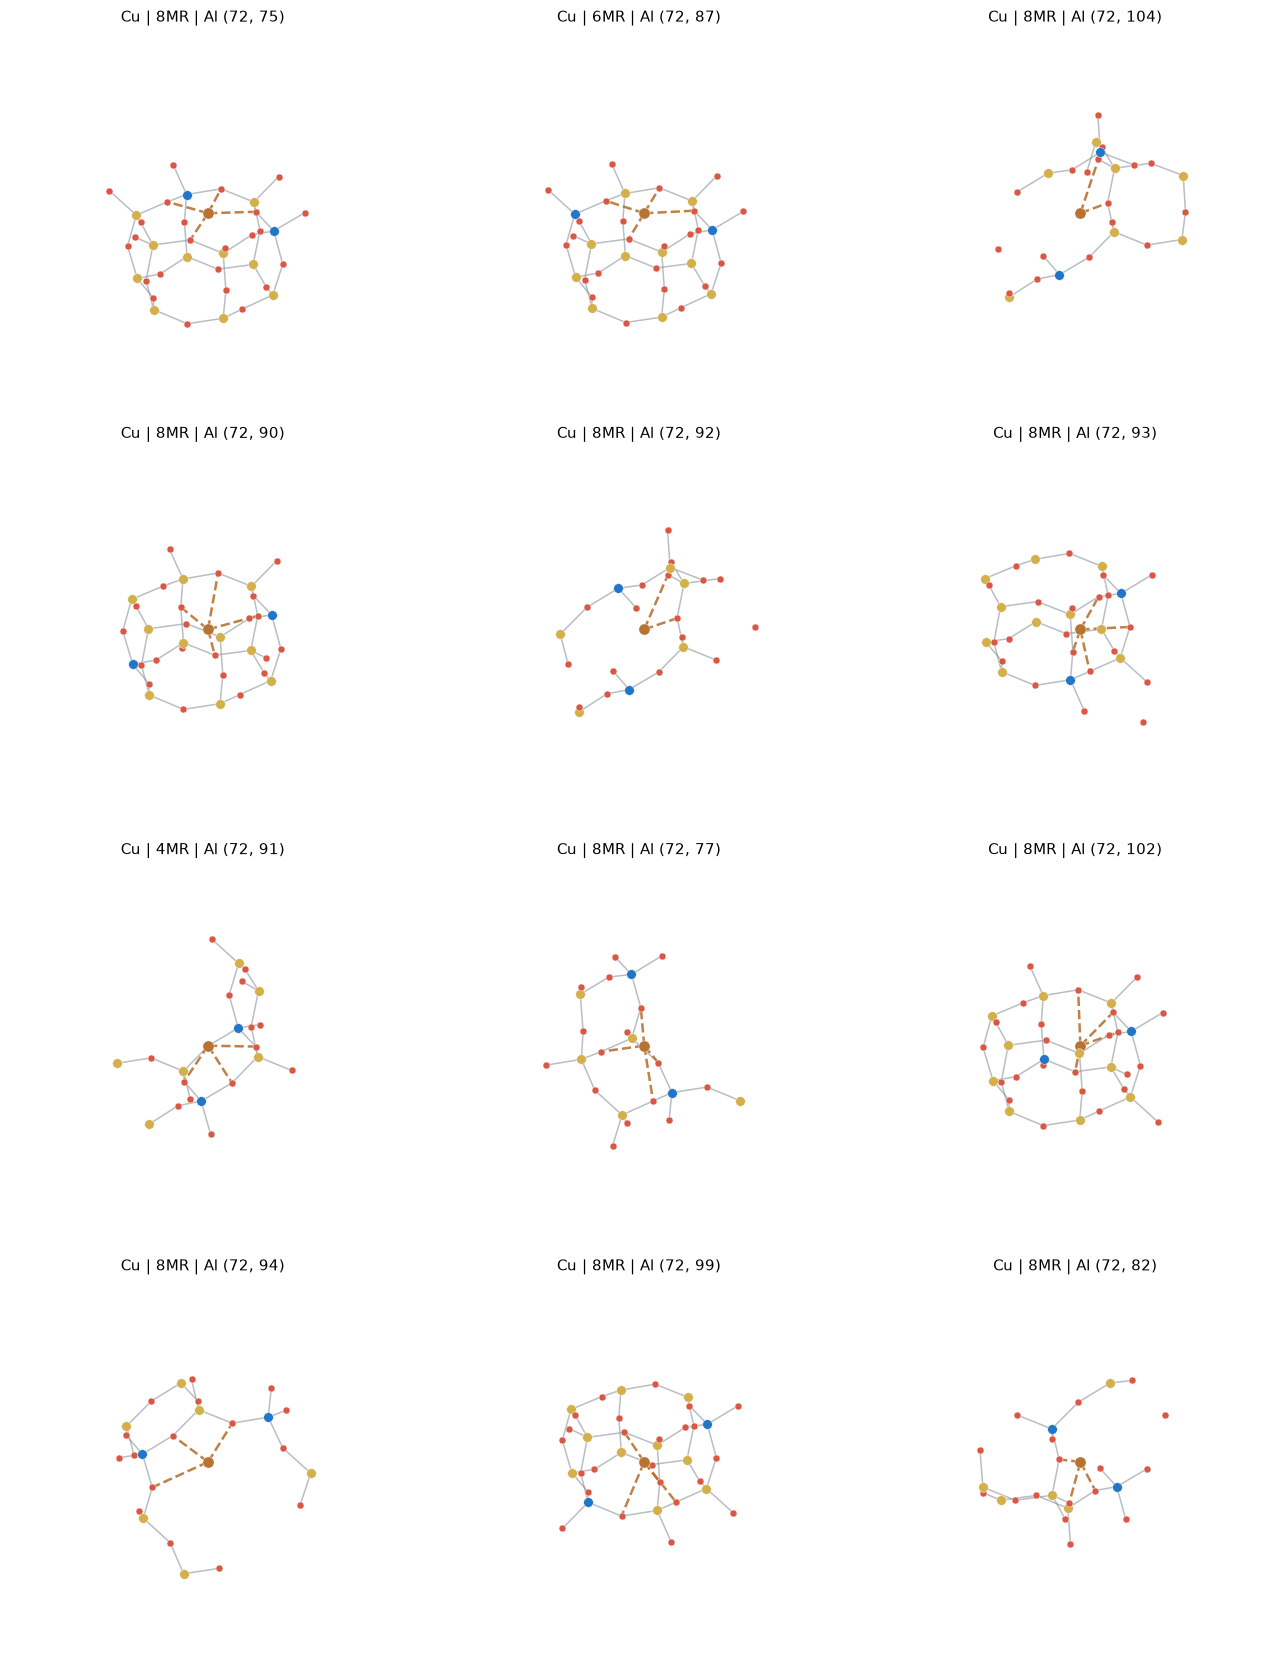

In [183]:
structures = [s.atoms for s in sites]
metal_indices = [len(s.atoms) - 1 for s in sites]
highlights = [list(s.al_indices) + [len(s.atoms) - 1] for s in sites]
titles = [
    f"{s.metal} | {s.ring_size}MR | Al {s.al_indices}"
    for s in sites
]

fig = plot_structure_grid(
    structures,
    center_indices=metal_indices,
    cation_indices=metal_indices,
    highlight_indices=None,
    titles=titles,
    radius=5,
    ncols=3,
    coord_cutoff=2.7,
    ring_overlays=False
)

plt.show()

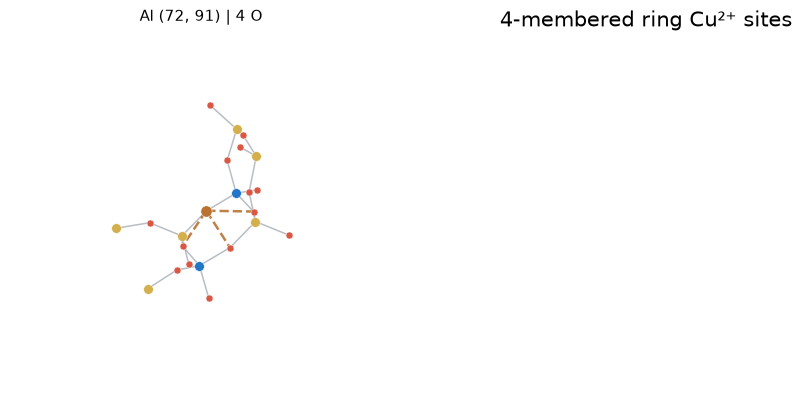

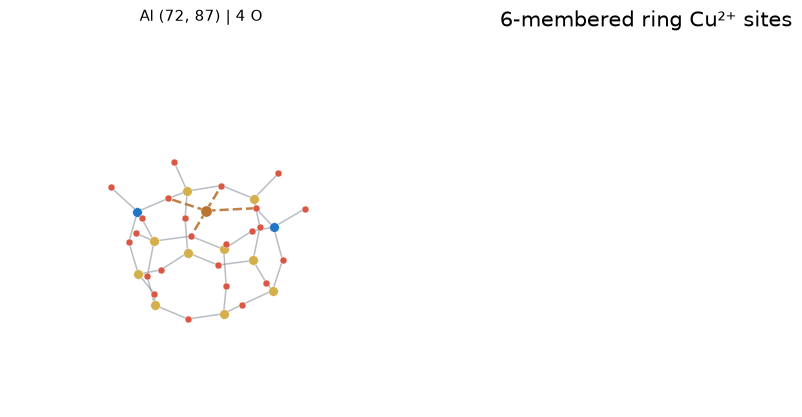

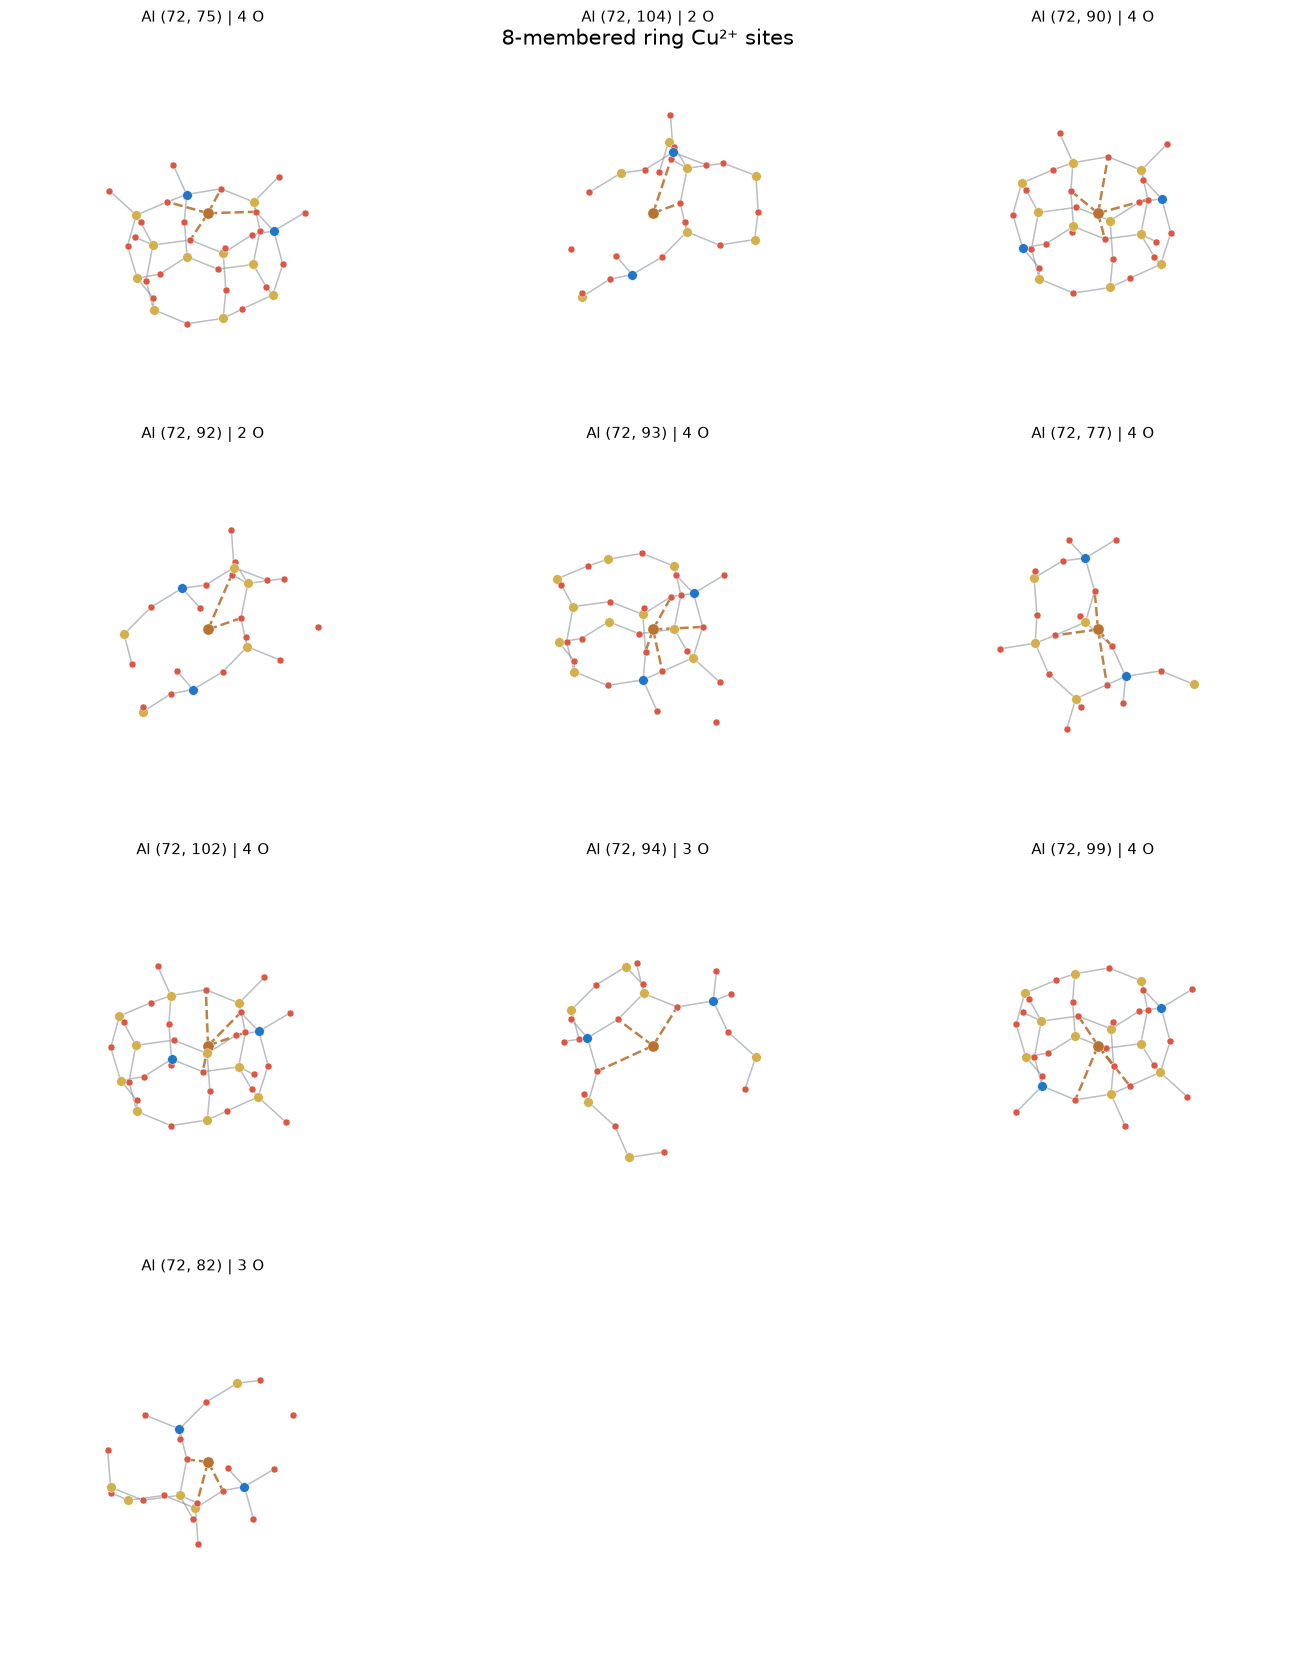

In [184]:
for ring_size in generator.ring_sizes:
    selected = [s for s in sites if s.ring_size == ring_size]

    if not selected:
        continue

    structures = [s.atoms for s in selected]
    metal_indices = [len(s.atoms) - 1 for s in selected]
    highlights = [list(s.al_indices) + [len(s.atoms) - 1] for s in selected]
    titles = [f"Al {s.al_indices} | {s.diagnostics['coordination_count']} O" for s in selected]

    fig = plot_structure_grid(
        structures,
        center_indices=metal_indices,
        cation_indices=metal_indices,
        highlight_indices=None,
        titles=titles,
        radius=5,
        ncols=3,
        coord_cutoff=2.7
    )

    fig.suptitle(f"{ring_size}-membered ring Cu²⁺ sites", fontsize=15)
    plt.show()

In [185]:

df = generator.summary(sites)

print("Total structures:", len(sites))
print("Unique Al pairs:", df.al_pair.nunique())

print("\nStructures by ring size:")
display(df.groupby("ring_size").agg(
    n_structures=("al_pair", "size"),
    n_al_pairs=("al_pair", "nunique"),
    n_clashes=("potential_clash", "sum")
))

print("\nAl pairs represented:")
display(
    df.groupby("al_pair")
      .agg(ring_sizes=("ring_size", lambda x: tuple(sorted(set(x)))),
           n_structures=("ring_size", "size"),
           min_mo_A=("min_mo_A", "min"))
      .reset_index()
)


Total structures: 12
Unique Al pairs: 12

Structures by ring size:


,n_structures,n_al_pairs,n_clashes
ring_size,,,
4,1,1,1
6,1,1,0
8,10,10,6



Al pairs represented:


,al_pair,ring_sizes,n_structures,min_mo_A
0,"(72, 75)","(8,)",1,2.103552
1,"(72, 77)","(8,)",1,2.252840
2,"(72, 82)","(8,)",1,1.901366
3,"(72, 87)","(6,)",1,2.218840
4,"(72, 90)","(8,)",1,1.979696
5,"(72, 91)","(4,)",1,1.934082
6,"(72, 92)","(8,)",1,2.328054
7,"(72, 93)","(8,)",1,1.924134
8,"(72, 94)","(8,)",1,2.055143
9,"(72, 99)","(8,)",1,2.183061


In [186]:

def get_shared_ring_sizes(generator, al_pair):
    pair = set(al_pair)
    return tuple(sorted({
        ring["size"]
        for ring in generator.rings
        if pair.issubset(ring["t_indices"])
    }))


rows = []

for site in sites:
    rows.append({
        "al_pair": site.al_indices,
        "assigned_ring": site.ring_size,
        "shared_rings": get_shared_ring_sizes(generator, site.al_indices),
        "coordination": site.diagnostics["coordination_count"],
        "clash": site.diagnostics["potential_clash"]
    })

site_rings_df = pd.DataFrame(rows)
display(site_rings_df)


,al_pair,assigned_ring,shared_rings,coordination,clash
0,"(72, 75)",8,"(6, 8)",4,False
1,"(72, 87)",6,"(6, 8)",4,False
2,"(72, 104)",8,"(8,)",2,False
3,"(72, 90)",8,"(8,)",4,False
4,"(72, 92)",8,"(8,)",2,False
5,"(72, 93)",8,"(4, 8)",4,True
6,"(72, 91)",4,"(4,)",4,True
7,"(72, 77)",8,"(8,)",4,True
8,"(72, 102)",8,"(8,)",4,True
9,"(72, 94)",8,"(8,)",3,True


In [187]:

def classify_6mr_pair(generator, al_pair):
    pair = set(al_pair)
    arrangements = set()

    for ring in generator.rings:
        if ring["size"] != 6 or not pair.issubset(ring["t_indices"]):
            continue

        indices = list(ring["t_indices"])
        a, b = [indices.index(i) for i in al_pair]
        separation = min(abs(a-b), 6-abs(a-b))

        if separation == 2:
            arrangements.add("meta")
        elif separation == 3:
            arrangements.add("para")

    return tuple(sorted(arrangements))


site_rings_df["6mr_arrangement"] = [
    classify_6mr_pair(generator, pair)
    for pair in site_rings_df.al_pair
]

display(site_rings_df)


,al_pair,assigned_ring,shared_rings,coordination,clash,6mr_arrangement
0,"(72, 75)",8,"(6, 8)",4,False,"(meta,)"
1,"(72, 87)",6,"(6, 8)",4,False,"(para,)"
2,"(72, 104)",8,"(8,)",2,False,()
3,"(72, 90)",8,"(8,)",4,False,()
4,"(72, 92)",8,"(8,)",2,False,()
5,"(72, 93)",8,"(4, 8)",4,True,()
6,"(72, 91)",4,"(4,)",4,True,()
7,"(72, 77)",8,"(8,)",4,True,()
8,"(72, 102)",8,"(8,)",4,True,()
9,"(72, 94)",8,"(8,)",3,True,()


In [188]:
rows = []

for site in sites:
    d = site.diagnostics

    rows.append({
        "al_pair": site.al_indices,
        "ring": site.ring_size,
        "coordination": d["coordination_count"],
        "min_Cu_O_A": round(d["min_mo_A"], 3),
        "min_Cu_T_A": round(d["min_mt_A"], 3),
        "Cu_O_clash": d["min_mo_A"] < 1.8,
        "Cu_T_clash": d["min_mt_A"] < 2.4,
        "placement_score": round(d.get("placement_score", np.nan), 3)
    })

clash_df = pd.DataFrame(rows)
display(clash_df)

,al_pair,ring,coordination,min_Cu_O_A,min_Cu_T_A,Cu_O_clash,Cu_T_clash,placement_score
0,"(72, 75)",8,4,2.104,2.775,False,False,1.236
1,"(72, 87)",6,4,2.219,2.924,False,False,1.589
2,"(72, 104)",8,2,1.867,2.673,False,False,6.205
3,"(72, 90)",8,4,1.980,2.492,False,False,6.492
4,"(72, 92)",8,2,2.328,3.016,False,False,10.035
5,"(72, 93)",8,4,1.924,2.372,False,True,0.212
6,"(72, 91)",4,4,1.934,2.375,False,True,0.236
7,"(72, 77)",8,4,2.253,2.330,False,True,1.732
8,"(72, 102)",8,4,2.215,2.348,False,True,1.739
9,"(72, 94)",8,3,2.055,2.359,False,True,2.940
